In [ ]:
!pip -q install -U xgboost lightgbm
import os
import random
import math
import time
import copy
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import OrderedDict
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (accuracy_score,precision_recall_fscore_support,classification_report,confusion_matrix,roc_auc_score,roc_curve)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import (RandomForestClassifier,GradientBoostingClassifier,ExtraTreesClassifier,HistGradientBoostingClassifier)
from scipy.stats import wilcoxon
#from statsmodels.stats.multitest import multipletests
import xgboost as xgb
import lightgbm as lgb
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
seed_everything(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
from google.colab import files

uploaded = files.upload()
print("\nUploaded files:")
for filename in uploaded.keys():print(" -", filename)
if "KDDTrain.txt" in uploaded:
    TRAIN_PATH = "/content/KDDTrain.txt"
elif "KDDTrain+.txt" in uploaded:
    TRAIN_PATH = "/content/KDDTrain+.txt"
else:
    raise FileNotFoundError(
        "Training file not found. Please upload KDDTrain.txt "
        "or KDDTrain+.txt")

if "KDDTest.txt" in uploaded:
    TEST_PATH = "/content/KDDTest.txt"
elif "KDDTest+.txt" in uploaded:
    TEST_PATH = "/content/KDDTest+.txt"
else:
    raise FileNotFoundError(
        "Testing file not found. Please upload KDDTest.txt "
        "or KDDTest+.txt")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.5/3.5 MB 35.2 MB/s eta 0:00:00


Saving KDDTest+.txt to KDDTest+.txt
Saving KDDTrain+.txt to KDDTrain+.txt

Uploaded files:
 - KDDTest+.txt
 - KDDTrain+.txt


#preprocessing

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
FEATURES = [
    "duration","protocol_type","service","flag","src_bytes","dst_bytes","land",
    "wrong_fragment","urgent","hot","num_failed_logins","logged_in","num_compromised",
    "root_shell","su_attempted","num_root","num_file_creations","num_shells","num_access_files",
    "num_outbound_cmds","is_host_login","is_guest_login","count","srv_count","serror_rate",
    "srv_serror_rate","rerror_rate","srv_rerror_rate","same_srv_rate","diff_srv_rate","srv_diff_host_rate",
    "dst_host_count","dst_host_srv_count","dst_host_same_srv_rate","dst_host_diff_srv_rate","dst_host_same_src_port_rate","dst_host_srv_diff_host_rate",
    "dst_host_serror_rate","dst_host_srv_serror_rate","dst_host_rerror_rate","dst_host_srv_rerror_rate"]
COLS = FEATURES + ["label", "difficulty"]
train_raw = pd.read_csv(TRAIN_PATH,header=0,names=COLS)
test_raw = pd.read_csv(TEST_PATH,header=None, names=COLS)

train_raw["label"] = (train_raw["label"].astype(str).str.strip().str.lower())
test_raw["label"] = (test_raw["label"].astype(str).str.strip().str.lower())

before = len(train_raw)
train_raw = (train_raw.drop_duplicates().reset_index(drop=True))
duplicates_removed = before - len(train_raw)
print("\n" + "=" * 70)
print("DUPLICATE REMOVAL")
print("=" * 70)
print(f"Training duplicates removed : {duplicates_removed}")
print(f"Unique training rows        : {len(train_raw)}")

ATTACK_MAP = {"normal": "Normal","dos": "DoS","probe": "Probe","r2l": "R2L","u2r": "U2R"}

train_raw["class_name"] = train_raw["label"].map(ATTACK_MAP)
test_raw["class_name"] = test_raw["label"].map(ATTACK_MAP)

unknown_train = sorted(train_raw.loc[train_raw["class_name"].isna(),"label"].unique())
unknown_test = sorted(test_raw.loc[ test_raw["class_name"].isna(), "label"].unique())

if unknown_train:
    raise ValueError(f"Unknown training labels found: {unknown_train}\n"f"Expected labels: {list(ATTACK_MAP.keys())}")
if unknown_test:
    raise ValueError(f"Unknown testing labels found: {unknown_test}\n"f"Expected labels: {list(ATTACK_MAP.keys())}")

CLASS_NAMES = ["Normal", "DoS","Probe","R2L", "U2R"]
CLASS_TO_ID = {
    class_name: idx
    for idx, class_name in enumerate(CLASS_NAMES)}
ID_TO_CLASS = {
    idx: class_name
    for class_name, idx in CLASS_TO_ID.items()}

y_train = (train_raw["class_name"].map(CLASS_TO_ID).to_numpy(dtype=np.int64))
y_test = (test_raw["class_name"].map(CLASS_TO_ID).to_numpy(dtype=np.int64))
Xtr_df = train_raw[FEATURES].copy()
Xte_df = test_raw[FEATURES].copy()
CAT_COLS = ["protocol_type","service","flag"]

encoders = {}
for col in CAT_COLS:
    train_values = (Xtr_df[col].astype(str).str.strip())
    test_values = (Xte_df[col].astype(str).str.strip())
    categories = sorted( train_values.unique())
    mapping = {
        value: idx
        for idx, value in enumerate(categories)}
    encoders[col] = mapping
    Xtr_df[col] = (train_values.map(mapping).astype(np.float32))
    Xte_df[col] = (test_values.map(lambda value: mapping.get(value,len(mapping))).astype(np.float32))
    print(f"\nEncoded '{col}': "f"{len(mapping)} training categories")
X_train_raw = Xtr_df.to_numpy(dtype=np.float32)
X_test_raw = Xte_df.to_numpy(dtype=np.float32)

scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train_raw).astype(np.float32)
X_test = scaler.transform(X_test_raw).astype(np.float32)

assert X_train.shape[0] == len(y_train)
assert X_test.shape[0] == len(y_test)
assert X_train.shape[1] == len(FEATURES)
assert X_test.shape[1] == len(FEATURES)
assert np.isfinite(X_train).all()
assert np.isfinite(X_test).all()
assert not pd.isna(y_train).any()
assert not pd.isna(y_test).any()

train_distribution = (pd.Series(y_train).map(ID_TO_CLASS).value_counts().reindex(CLASS_NAMES, fill_value=0))
test_distribution = (pd.Series(y_test).map(ID_TO_CLASS).value_counts().reindex(CLASS_NAMES, fill_value=0))

print("\n✓ CELL 2 completed successfully.")


DUPLICATE REMOVAL
Training duplicates removed : 4
Unique training rows        : 88176

Encoded 'protocol_type': 3 training categories

Encoded 'service': 69 training categories

Encoded 'flag': 11 training categories

✓ CELL 2 completed successfully.


#Autoencoder

In [ ]:
# ============================================================
# AUTOENCODER WITH TRAINING + VALIDATION LOSS
# Test data remains completely untouched
# ============================================================

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

class Autoencoder(nn.Module):
    def __init__(self, input_dim=41, latent_dim=16):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(input_dim, 64), nn.ReLU(),nn.Linear(64, 32), nn.ReLU(),nn.Linear(32, latent_dim))
        self.decoder = nn.Sequential(nn.Linear(latent_dim, 32), nn.ReLU(),nn.Linear(32, 64), nn.ReLU(),nn.Linear(64, input_dim), nn.Sigmoid())

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z), z

AE_EPOCHS = 50
AE_BATCH = 32
AE_LR = 1e-3
LATENT_DIM = 16
AE_VAL_SIZE = 0.20

X_ae_train, X_ae_val = train_test_split(X_train, test_size=AE_VAL_SIZE, random_state=42, shuffle=True)
train_tensor = torch.from_numpy(X_ae_train.astype(np.float32))
val_tensor = torch.from_numpy(X_ae_val.astype(np.float32))
loader_ae_train = DataLoader(TensorDataset(train_tensor),batch_size=AE_BATCH,shuffle=True,pin_memory=torch.cuda.is_available())
loader_ae_val = DataLoader(TensorDataset(val_tensor), batch_size=AE_BATCH,shuffle=False,pin_memory=torch.cuda.is_available())

ae = Autoencoder(X_train.shape[1], LATENT_DIM).to(DEVICE)
opt_ae = torch.optim.Adam(ae.parameters(), lr=AE_LR)
criterion_ae = nn.MSELoss()
ae_history = {"train_loss": [], "val_loss": []}

for epoch in range(AE_EPOCHS):
    ae.train()
    train_total = 0.0

    for (xb,) in loader_ae_train:
        xb = xb.to(DEVICE, non_blocking=True)
        opt_ae.zero_grad(set_to_none=True)
        xhat, _ = ae(xb)
        loss = criterion_ae(xhat, xb)
        loss.backward()
        opt_ae.step()
        train_total += loss.item() * len(xb)
    train_loss = train_total / len(loader_ae_train.dataset)

    # ===== Validation =====
    ae.eval()
    val_total = 0.0
    with torch.no_grad():
        for (xb,) in loader_ae_val:
            xb = xb.to(DEVICE, non_blocking=True)
            xhat, _ = ae(xb)
            loss = criterion_ae(xhat, xb)
            val_total += loss.item() * len(xb)
    val_loss = val_total / len(loader_ae_val.dataset)
    ae_history["train_loss"].append(train_loss)
    ae_history["val_loss"].append(val_loss)

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"Epoch {epoch + 1:03d}/{AE_EPOCHS} | "f"Train Loss = {train_loss:.6f} | "f"Val Loss = {val_loss:.6f}")
best_epoch = np.argmin(ae_history["val_loss"]) + 1
best_val_loss = np.min(ae_history["val_loss"])

ae.eval()
with torch.no_grad():
    Z_train = ae.encoder(torch.from_numpy(X_train.astype(np.float32)).to(DEVICE)).cpu().numpy().astype(np.float32)
latent_scaler = MinMaxScaler()
Z_train_n = latent_scaler.fit_transform(Z_train).astype(np.float32)

Epoch 001/50 | Train Loss = 0.015323 | Val Loss = 0.006754
Epoch 005/50 | Train Loss = 0.001533 | Val Loss = 0.001270
Epoch 010/50 | Train Loss = 0.000684 | Val Loss = 0.000677
Epoch 015/50 | Train Loss = 0.000481 | Val Loss = 0.000460
Epoch 020/50 | Train Loss = 0.000415 | Val Loss = 0.000401
Epoch 025/50 | Train Loss = 0.000378 | Val Loss = 0.000404
Epoch 030/50 | Train Loss = 0.000352 | Val Loss = 0.000350
Epoch 035/50 | Train Loss = 0.000336 | Val Loss = 0.000356
Epoch 040/50 | Train Loss = 0.000324 | Val Loss = 0.000328
Epoch 045/50 | Train Loss = 0.000313 | Val Loss = 0.000301
Epoch 050/50 | Train Loss = 0.000299 | Val Loss = 0.000324


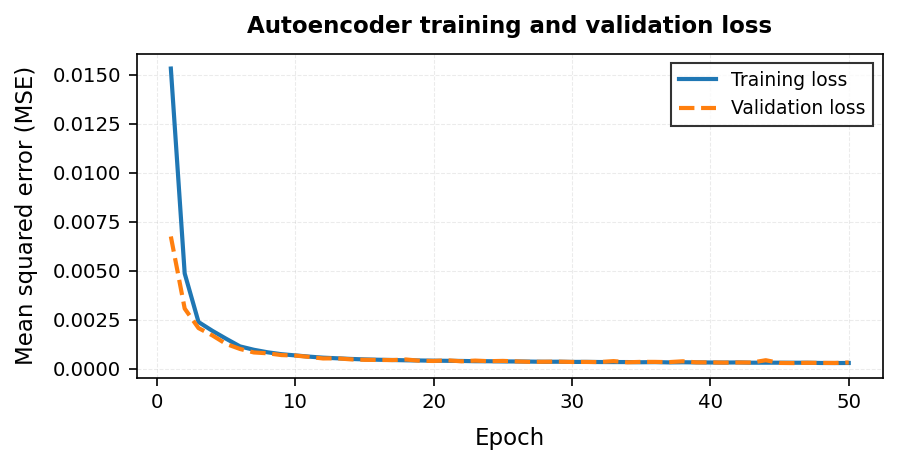

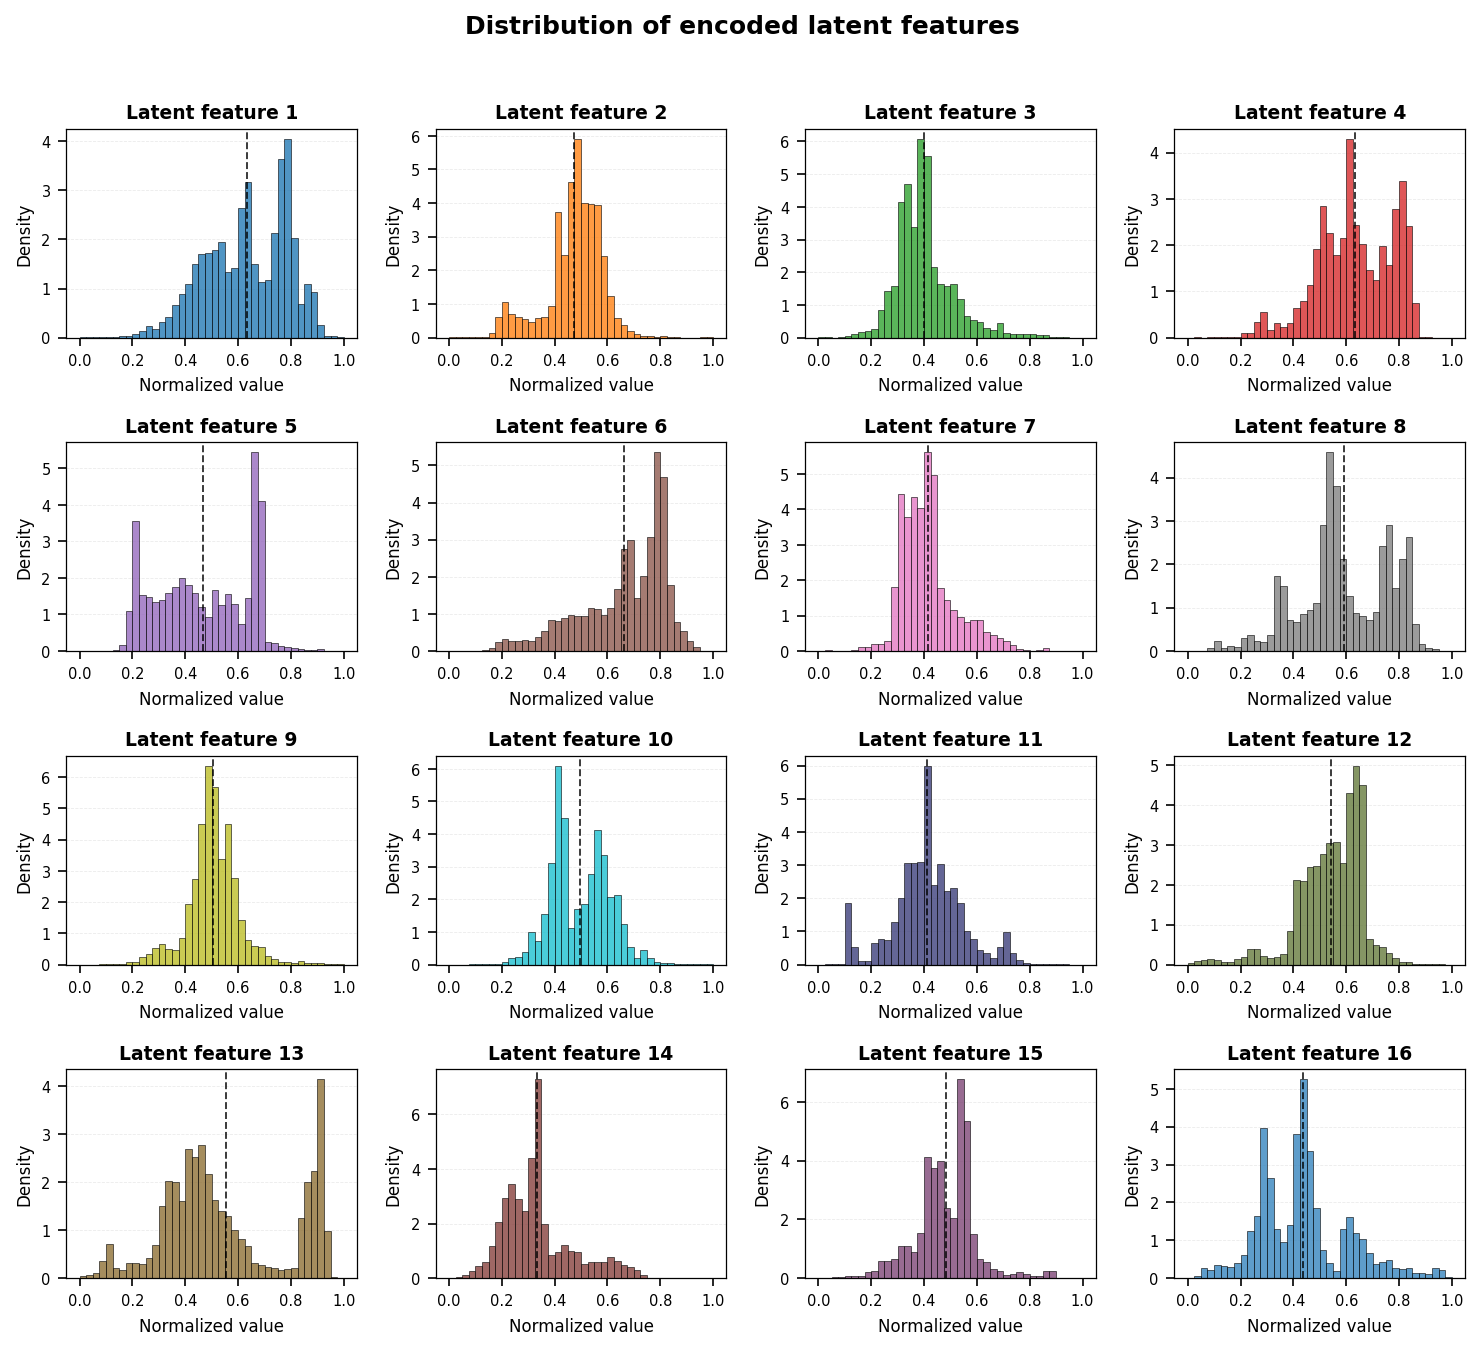

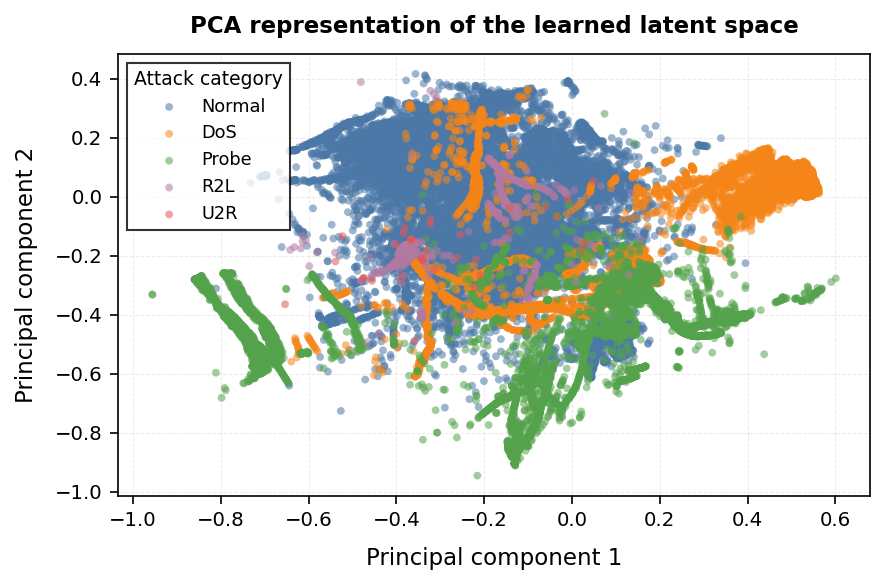

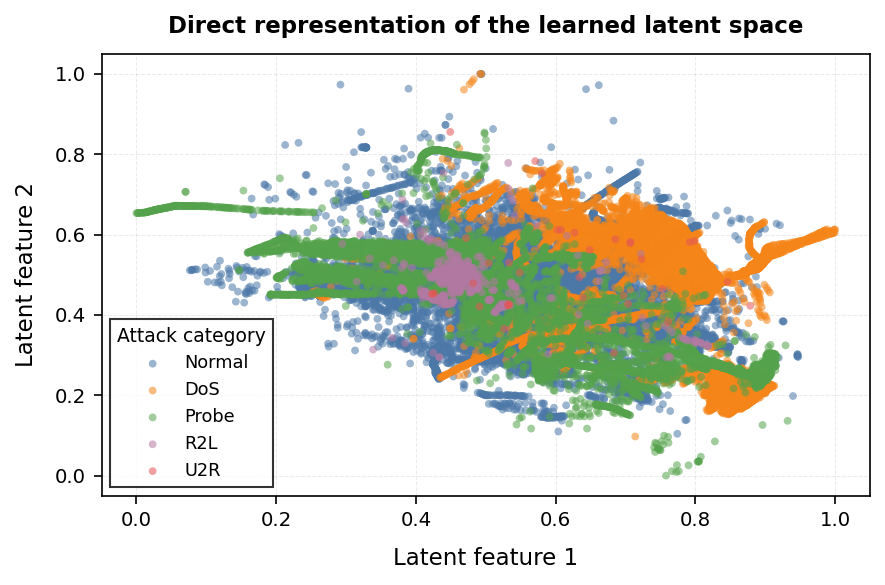

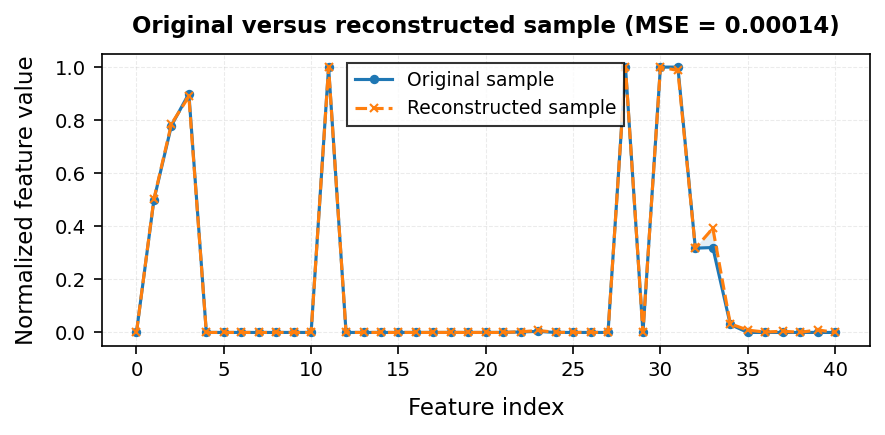

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.decomposition import PCA

plt.rcParams.update({
    "font.family": "DejaVu Sans","font.size": 10,"axes.labelsize": 11,"axes.titlesize": 11,
    "xtick.labelsize": 9.5,"ytick.labelsize": 9.5,"legend.fontsize": 9,"axes.linewidth": 0.8,"xtick.major.width": 0.8,"ytick.major.width": 0.8,
    "xtick.major.size": 4,"ytick.major.size": 4,"figure.dpi": 150,"savefig.dpi": 600,"pdf.fonttype": 42,"ps.fonttype": 42,"axes.spines.top": True,"axes.spines.right": True})
output_dir = Path("publication_figures")
output_dir.mkdir(parents=True, exist_ok=True)

CLASS_COLORS = ["#4C78A8", "#F58518",   "#54A24B",  "#B279A2",  "#E45756"  ]
LATENT_COLORS = [
    "#1F77B4","#FF7F0E","#2CA02C","#D62728","#9467BD","#8C564B","#E377C2","#7F7F7F",
    "#BCBD22","#17BECF","#393B79","#637939","#8C6D31","#843C39","#7B4173","#3182BD"]
def save_publication_figure(fig, filename):
    fig.savefig(output_dir / f"{filename}.tif", dpi=600, format="tiff", bbox_inches="tight", pad_inches=0.05, facecolor="white", edgecolor="black", pil_kwargs={"compression": "tiff_lzw"})
    fig.savefig(output_dir / f"{filename}.pdf", format="pdf", bbox_inches="tight", pad_inches=0.05, facecolor="white", edgecolor="black")
    fig.savefig(output_dir / f"{filename}.png", dpi=600, format="png", bbox_inches="tight", pad_inches=0.05, facecolor="white", edgecolor="black")

epochs = np.arange(1, len(ae_history["train_loss"]) + 1)
fig4, ax4 = plt.subplots(figsize=(6, 3.2))
ax4.plot(epochs, ae_history["train_loss"], linewidth=2.0, label="Training loss")
ax4.plot(epochs, ae_history["val_loss"], linewidth=2.0, linestyle="--", label="Validation loss")
ax4.set_xlabel("Epoch", labelpad=7)
ax4.set_ylabel("Mean squared error (MSE)", labelpad=7)
ax4.set_title("Autoencoder training and validation loss", fontweight="bold", pad=10)
ax4.grid(axis="both", linestyle="--", linewidth=0.5, alpha=0.25)
ax4.set_axisbelow(True)
ax4.legend(frameon=True, edgecolor="black", fancybox=False, loc="best")

for spine in ax4.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(0.8)
fig4.tight_layout()
save_publication_figure(fig4, "Fig4_Autoencoder_Loss")
plt.show()
plt.close(fig4)

latent_dim = Z_train_n.shape[1]
n_cols = 4
n_rows = int(np.ceil(latent_dim / n_cols))
fig6, axes6 = plt.subplots(n_rows, n_cols, figsize=(10.0, 2.25 * n_rows))
axes6 = np.asarray(axes6).flatten()
for i in range(latent_dim):
    ax = axes6[i]
    latent_color = LATENT_COLORS[i % len(LATENT_COLORS)]
    ax.hist(Z_train_n[:, i],bins=40,density=True,color=latent_color,edgecolor="black",linewidth=0.35,alpha=0.78)
    ax.axvline(np.mean(Z_train_n[:, i]),color="black",linestyle="--",linewidth=0.9,alpha=0.8)
    ax.set_title(f"Latent feature {i + 1}", fontsize=9, fontweight="bold", pad=5)
    ax.set_xlabel("Normalized value", fontsize=8)
    ax.set_ylabel("Density", fontsize=8)
    ax.tick_params(axis="both", labelsize=7)
    ax.grid(axis="y", linestyle="--", linewidth=0.4, alpha=0.25)
    ax.set_axisbelow(True)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.6)
        spine.set_color("black")

for i in range(latent_dim, len(axes6)):
    axes6[i].set_visible(False)

fig6.suptitle("Distribution of encoded latent features", fontsize=12, fontweight="bold", y=0.995)
fig6.tight_layout(rect=[0, 0, 1, 0.98])
save_publication_figure(fig6, "Fig6_Encoded_Feature_Distribution")
plt.show()
plt.close(fig6)

pca = PCA(n_components=2, random_state=42)
Z_pca = pca.fit_transform(Z_train_n)
explained_variance = pca.explained_variance_ratio_ * 100
pc1_variance = explained_variance[0]
pc2_variance = explained_variance[1]
total_variance = pc1_variance + pc2_variance

fig7, ax7 = plt.subplots(figsize=(6, 4))
for class_id, class_name in enumerate(CLASS_NAMES):
    mask = y_train == class_id
    if np.sum(mask) == 0:
        continue
    ax7.scatter(
        Z_pca[mask, 0],Z_pca[mask, 1],s=14,alpha=0.55,
        color=CLASS_COLORS[class_id],edgecolors="none",label=class_name)

ax7.set_xlabel(f"Principal component 1", labelpad=8)
ax7.set_ylabel(f"Principal component 2", labelpad=8)
ax7.set_title("PCA representation of the learned latent space", fontsize=11, fontweight="bold", pad=10)
ax7.grid(linestyle="--", linewidth=0.5, alpha=0.25)
ax7.set_axisbelow(True)
ax7.legend(title="Attack category", frameon=True, edgecolor="black", fancybox=False, loc="best", fontsize=8.5, title_fontsize=9)
for spine in ax7.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(0.8)
fig7.tight_layout()
save_publication_figure(fig7, "Fig7_PCA_Latent_Space")
plt.show()
plt.close(fig7)

fig8, ax8 = plt.subplots(figsize=(6, 4))
for class_id, class_name in enumerate(CLASS_NAMES):
    mask = y_train == class_id
    if np.sum(mask) == 0:
        continue
    ax8.scatter(
        Z_train_n[mask, 0],Z_train_n[mask, 1],s=14,alpha=0.55,
        color=CLASS_COLORS[class_id],edgecolors="none",label=class_name)

ax8.set_xlabel("Latent feature 1", labelpad=8)
ax8.set_ylabel("Latent feature 2", labelpad=8)
ax8.set_title("Direct representation of the learned latent space", fontsize=11, fontweight="bold", pad=10)
ax8.grid(linestyle="--", linewidth=0.5, alpha=0.25)
ax8.set_axisbelow(True)
ax8.legend(title="Attack category", frameon=True, edgecolor="black", fancybox=False, loc="best", fontsize=8.5, title_fontsize=9)
for spine in ax8.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(0.8)
fig8.tight_layout()
save_publication_figure(fig8, "Fig8_Direct_Latent_Space")
plt.show()
plt.close(fig8)
sample_index = 0

ae.eval()
with torch.no_grad():
    X_test_tensor = torch.tensor(X_test, dtype=torch.float32).to(DEVICE)
    X_test_reconstructed_n = ae(X_test_tensor)[0].cpu().numpy()
original_sample = np.asarray(X_test[sample_index]).flatten()
reconstructed_sample = np.asarray(X_test_reconstructed_n[sample_index]).flatten()
feature_indices = np.arange(len(original_sample))
sample_mse = np.mean((original_sample - reconstructed_sample) ** 2)
sample_mae = np.mean(np.abs(original_sample - reconstructed_sample))

fig9, ax9 = plt.subplots(figsize=(6, 3))
ax9.plot(feature_indices,original_sample,marker="o",markersize=3.5,linewidth=1.5,label="Original sample")
ax9.plot(feature_indices,reconstructed_sample,marker="x",markersize=4,linewidth=1.5,linestyle="--",label="Reconstructed sample")
ax9.fill_between(feature_indices,original_sample,reconstructed_sample,alpha=0.12)

ax9.set_xlabel("Feature index", labelpad=8)
ax9.set_ylabel("Normalized feature value", labelpad=8)
ax9.set_title(f"Original versus reconstructed sample (MSE = {sample_mse:.5f})",fontsize=11,fontweight="bold",pad=10)
ax9.grid(linestyle="--",linewidth=0.5,alpha=0.25)
ax9.set_axisbelow(True)
ax9.legend(frameon=True,edgecolor="black",fancybox=False,loc="best")

for spine in ax9.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(0.8)

fig9.tight_layout()
save_publication_figure(fig9,"Fig9_Original_vs_Reconstructed_Sample")
plt.show()
plt.close(fig9)

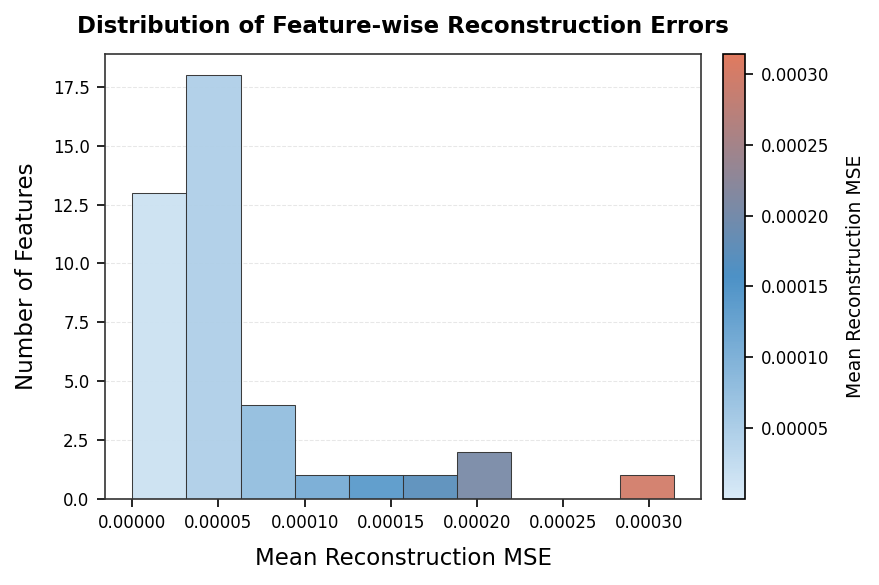

In [ ]:
# ============================================================
# Feature-wise Reconstruction Error Distribution
# ============================================================

ae.eval()
with torch.no_grad():
    X_train_tensor = torch.from_numpy(X_train.astype(np.float32)).to(DEVICE)
    X_reconstructed = ae(X_train_tensor)[0].cpu().numpy()

feature_errors = np.mean((X_train - X_reconstructed) ** 2, axis=0)

fig5, ax5 = plt.subplots(figsize=(6, 4))
cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list("publication_blue_orange", ["#D9EAF7", "#4C91C6", "#E07A5F"])
norm = plt.Normalize(feature_errors.min(), feature_errors.max())
counts, bins, patches = ax5.hist(feature_errors, bins=10, edgecolor="#333333", linewidth=0.5, alpha=0.95)
for patch, left, right in zip(patches, bins[:-1], bins[1:]):
    patch.set_facecolor(cmap(norm((left + right) / 2)))
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig5.colorbar(sm, ax=ax5, pad=0.03)
cbar.set_label("Mean Reconstruction MSE", fontsize=9, labelpad=8)
cbar.ax.tick_params(labelsize=8)
ax5.set_xlabel("Mean Reconstruction MSE", labelpad=7)
ax5.set_ylabel("Number of Features", labelpad=7)
ax5.set_title("Distribution of Feature-wise Reconstruction Errors", fontweight="bold", pad=10)
ax5.tick_params(axis="both", labelsize=8)
ax5.grid(axis="y", linestyle="--", color="#B0B0B0", linewidth=0.5, alpha=0.3)
ax5.set_axisbelow(True)
for spine in ax5.spines.values():
    spine.set_visible(True)
    spine.set_color("#333333")
    spine.set_linewidth(0.8)
fig5.tight_layout()
save_publication_figure(fig5, "Fig5_Featurewise_Reconstruction_Error")
plt.show()
plt.close(fig5)

# AC-GAN-GP

In [ ]:
class Generator(nn.Module):
    def __init__(self, noise_dim=100, n_classes=5, latent_dim=16):
        super().__init__()
        self.embed = nn.Embedding(n_classes, n_classes)
        self.net = nn.Sequential(
            nn.Linear(noise_dim+n_classes, 128),nn.LeakyReLU(0.2, inplace=True),nn.Linear(128, 256),
            nn.LeakyReLU(0.2, inplace=True),nn.Linear(256, latent_dim),nn.Sigmoid())
    def forward(self, z, y):
        return self.net(torch.cat([z, self.embed(y)], dim=1))

class Discriminator(nn.Module):
    def __init__(self, latent_dim=16, n_classes=5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Linear(latent_dim, 256),nn.LeakyReLU(0.2, inplace=True),nn.Linear(256, 128),nn.LeakyReLU(0.2, inplace=True))
        self.critic = nn.Linear(128, 1)
        self.classifier = nn.Linear(128, n_classes)
    def forward(self, x):
        h = self.features(x)
        return self.critic(h).view(-1), self.classifier(h)

def gradient_penalty(D, real, fake):
    alpha = torch.rand(real.size(0), 1, device=real.device)
    interp = (alpha*real + (1-alpha)*fake).requires_grad_(True)
    score, _ = D(interp)
    grad = torch.autograd.grad(score, interp, torch.ones_like(score),create_graph=True, retain_graph=True)[0]
    return ((grad.view(len(real),-1).norm(2,dim=1)-1)**2).mean()

In [ ]:
NOISE_DIM = 100
GAN_EPOCHS = 100
GAN_BATCH = 128
GAN_LR = 2e-4
GP_LAMBDA = 10.0
CLS_WEIGHT = 1.0

G = Generator(NOISE_DIM, len(CLASS_NAMES), LATENT_DIM).to(DEVICE)
D = Discriminator(LATENT_DIM, len(CLASS_NAMES)).to(DEVICE)
opt_G = torch.optim.Adam(G.parameters(), lr=GAN_LR, betas=(0.5,0.999))
opt_D = torch.optim.Adam(D.parameters(), lr=GAN_LR, betas=(0.5,0.999))
ce = nn.CrossEntropyLoss()

gan_loader = DataLoader(
    TensorDataset(torch.from_numpy(Z_train_n), torch.from_numpy(y_train).long()),
    batch_size=GAN_BATCH, shuffle=True, drop_last=True,pin_memory=torch.cuda.is_available())

gan_history = {"G":[],"D":[],"GP":[]}
for epoch in range(GAN_EPOCHS):
    g_sum=d_sum=gp_sum=0.0
    for real, yb in gan_loader:
        real, yb = real.to(DEVICE), yb.to(DEVICE)
        bs = len(real)
        noise = torch.randn(bs, NOISE_DIM, device=DEVICE)
        fake = G(noise, yb).detach()
        real_score, real_cls = D(real)
        fake_score, fake_cls = D(fake)
        gp = gradient_penalty(D, real, fake)
        d_loss = (-real_score.mean() + fake_score.mean()+ GP_LAMBDA*gp+ CLS_WEIGHT*(ce(real_cls,yb)+ce(fake_cls,yb)))
        opt_D.zero_grad(set_to_none=True); d_loss.backward(); opt_D.step()
        noise = torch.randn(bs, NOISE_DIM, device=DEVICE)
        fake = G(noise, yb)
        fake_score, fake_cls = D(fake)
        g_loss = -fake_score.mean() + CLS_WEIGHT*ce(fake_cls,yb)
        opt_G.zero_grad(set_to_none=True); g_loss.backward(); opt_G.step()
        g_sum += g_loss.item(); d_sum += d_loss.item(); gp_sum += gp.item()

    n_batches=len(gan_loader)
    gan_history["G"].append(g_sum/n_batches)
    gan_history["D"].append(d_sum/n_batches)
    gan_history["GP"].append(gp_sum/n_batches)
    print(f"Epoch {epoch+1:02d}/{GAN_EPOCHS} | G={gan_history['G'][-1]:.4f} | "
          f"D={gan_history['D'][-1]:.4f} | GP={gan_history['GP'][-1]:.4f}")

Epoch 01/100 | G=0.7963 | D=2.4661 | GP=0.0287
Epoch 02/100 | G=0.3857 | D=0.7644 | GP=0.0094
Epoch 03/100 | G=0.0490 | D=0.5763 | GP=0.0099
Epoch 04/100 | G=0.3392 | D=0.3672 | GP=0.0046
Epoch 05/100 | G=0.1168 | D=0.3106 | GP=0.0049
Epoch 06/100 | G=0.0466 | D=0.2599 | GP=0.0049
Epoch 07/100 | G=0.0494 | D=0.2426 | GP=0.0036
Epoch 08/100 | G=-0.0746 | D=0.2162 | GP=0.0036
Epoch 09/100 | G=-0.0653 | D=0.2013 | GP=0.0032
Epoch 10/100 | G=-0.0848 | D=0.1560 | GP=0.0027
Epoch 11/100 | G=-0.2506 | D=0.1611 | GP=0.0032
Epoch 12/100 | G=-0.3150 | D=0.1412 | GP=0.0028
Epoch 13/100 | G=-0.2595 | D=0.1432 | GP=0.0025
Epoch 14/100 | G=-0.3406 | D=0.1385 | GP=0.0027
Epoch 15/100 | G=-0.5377 | D=0.1307 | GP=0.0027
Epoch 16/100 | G=-0.3187 | D=0.1129 | GP=0.0027
Epoch 17/100 | G=-0.4498 | D=0.1136 | GP=0.0025
Epoch 18/100 | G=-0.4315 | D=0.1171 | GP=0.0029
Epoch 19/100 | G=-0.3916 | D=0.1145 | GP=0.0029
Epoch 20/100 | G=-0.3890 | D=0.1084 | GP=0.0028
Epoch 21/100 | G=-0.3666 | D=0.1070 | GP=0.0027

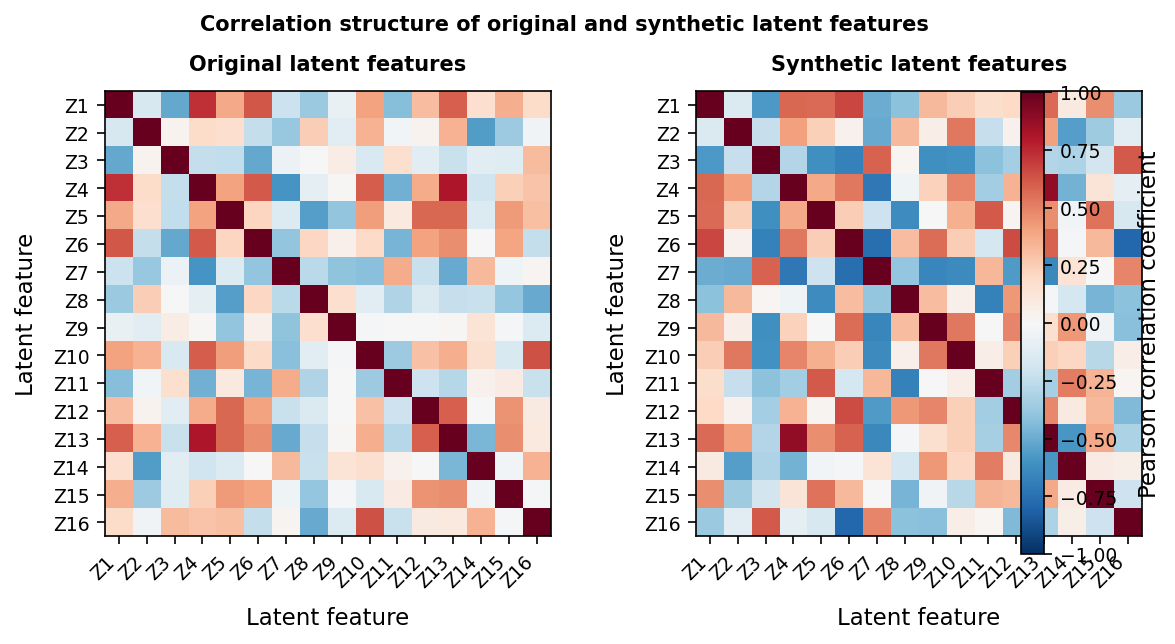

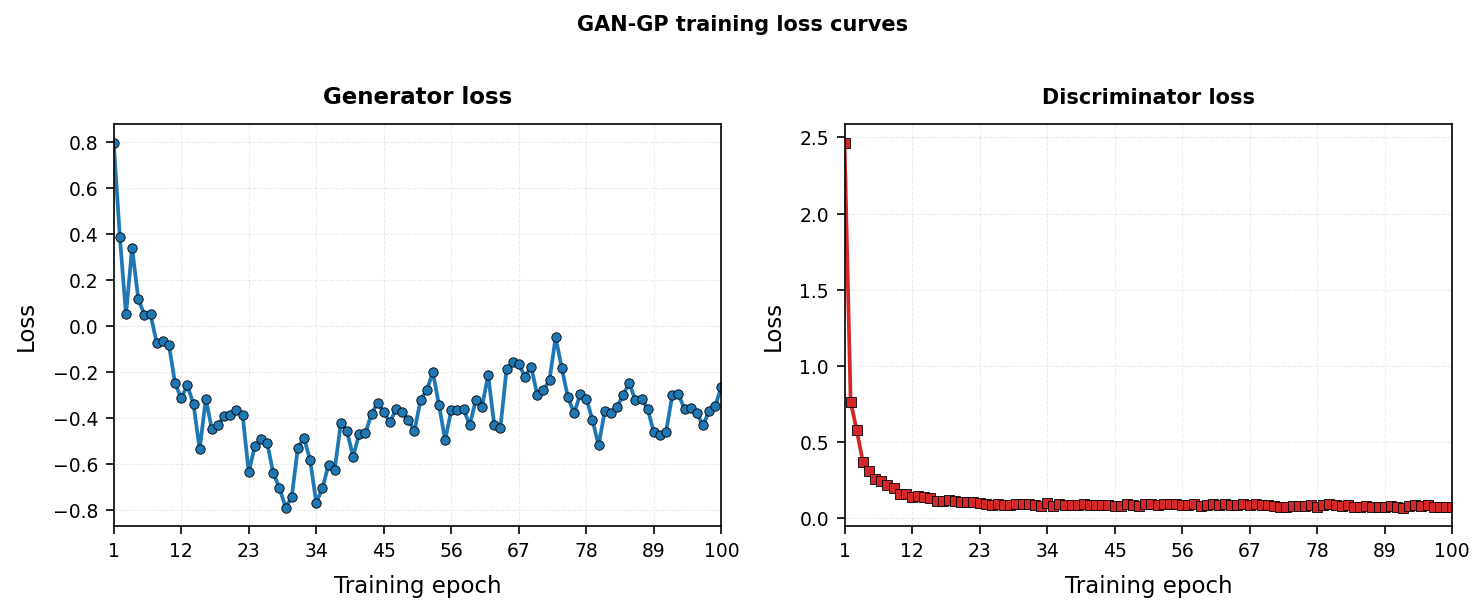

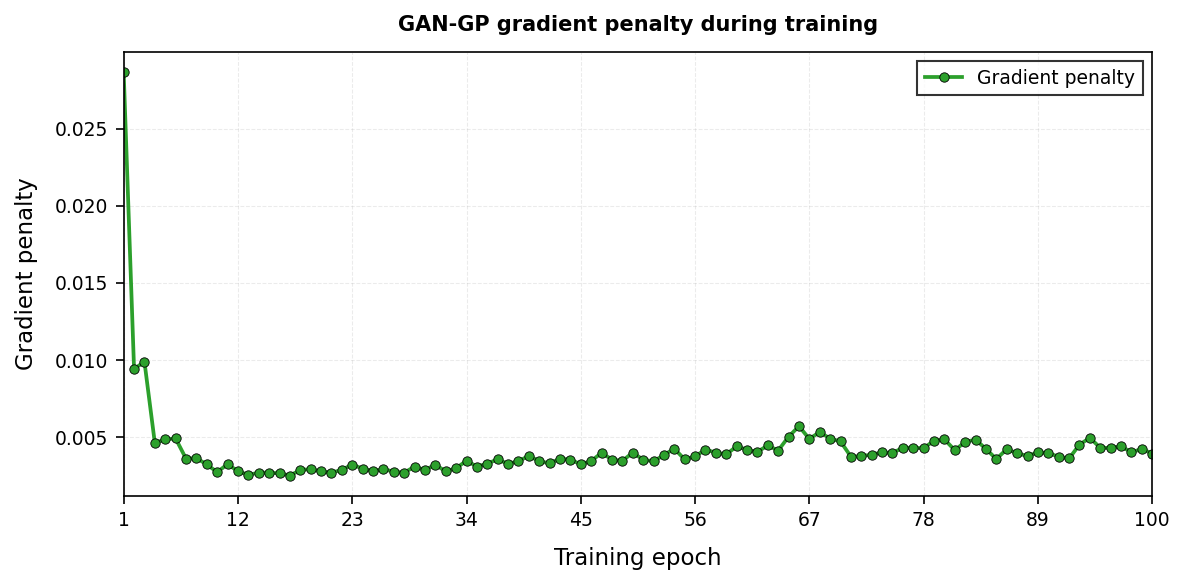

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["font.size"] = 10
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["axes.titlesize"] = 11
plt.rcParams["xtick.labelsize"] = 9
plt.rcParams["ytick.labelsize"] = 9
plt.rcParams["legend.fontsize"] = 9
plt.rcParams["axes.linewidth"] = 0.8
plt.rcParams["figure.dpi"] = 150
plt.rcParams["savefig.dpi"] = 600
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42

FIG_DIR = Path("publication_figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save_publication_figure(fig, filename):
    fig.savefig(FIG_DIR / f"{filename}.tif", dpi=600, bbox_inches="tight", facecolor="white", edgecolor="white", pil_kwargs={"compression": "tiff_lzw"})
    fig.savefig(FIG_DIR / f"{filename}.pdf", bbox_inches="tight", facecolor="white", edgecolor="white")
    fig.savefig(FIG_DIR / f"{filename}.png", dpi=600, bbox_inches="tight", facecolor="white", edgecolor="white")

G.eval()
synthetic_latent_list = []
synthetic_label_list = []
with torch.no_grad():
    for class_id in range(len(CLASS_NAMES)):
        class_indices = np.where(y_train == class_id)[0]
        n_generate = len(class_indices)
        y_syn = torch.full((n_generate,), class_id, dtype=torch.long, device=DEVICE)
        noise = torch.randn(n_generate, NOISE_DIM, device=DEVICE)
        synthetic_latent = G(noise, y_syn)
        synthetic_latent_list.append(synthetic_latent.cpu().numpy())
        synthetic_label_list.append(np.full(n_generate, class_id))
Z_synthetic = np.vstack(synthetic_latent_list)
y_synthetic = np.concatenate(synthetic_label_list)


original_corr = np.corrcoef(Z_train_n, rowvar=False)
synthetic_corr = np.corrcoef(Z_synthetic, rowvar=False)
latent_labels = [f"Z{i+1}" for i in range(LATENT_DIM)]
fig_corr, axes = plt.subplots(1, 2, figsize=(8, 4))
im1 = axes[0].imshow(original_corr, cmap="RdBu_r", vmin=-1, vmax=1, aspect="equal")

axes[0].set_title("Original latent features", fontsize=10, fontweight="bold", pad=10)
axes[0].set_xlabel("Latent feature", labelpad=7)
axes[0].set_ylabel("Latent feature", labelpad=7)
axes[0].set_xticks(np.arange(LATENT_DIM))
axes[0].set_yticks(np.arange(LATENT_DIM))
axes[0].set_xticklabels(latent_labels, rotation=45, ha="right")
axes[0].set_yticklabels(latent_labels)

im2 = axes[1].imshow(synthetic_corr, cmap="RdBu_r", vmin=-1, vmax=1, aspect="equal")
axes[1].set_title("Synthetic latent features", fontsize=10, fontweight="bold", pad=10)
axes[1].set_xlabel("Latent feature", labelpad=7)
axes[1].set_ylabel("Latent feature", labelpad=7)
axes[1].set_xticks(np.arange(LATENT_DIM))
axes[1].set_yticks(np.arange(LATENT_DIM))
axes[1].set_xticklabels(latent_labels, rotation=45, ha="right")
axes[1].set_yticklabels(latent_labels)

cbar = fig_corr.colorbar(im2, ax=axes.ravel().tolist(), fraction=0.025, pad=0.03)
cbar.set_label("Pearson correlation coefficient", rotation=90, labelpad=10)
for ax in axes:
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("black")
        spine.set_linewidth(0.8)
fig_corr.suptitle("Correlation structure of original and synthetic latent features", fontsize=10, fontweight="bold", y=1.01)
fig_corr.tight_layout()
save_publication_figure(fig_corr, "Fig17_Original_vs_Synthetic_Latent_Correlation")
plt.show()
plt.close(fig_corr)

epochs = np.arange(1, len(gan_history["G"]) + 1)
fig_loss, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(epochs, gan_history["G"], color="#1F77B4", marker="o", markersize=4.5, linewidth=1.8, markeredgecolor="black", markeredgewidth=0.4)
axes[0].set_title("Generator loss", fontsize=11, fontweight="bold", pad=10)
axes[0].set_xlabel("Training epoch", labelpad=7)
axes[0].set_ylabel("Loss", labelpad=7)
axes[0].grid(linestyle="--", linewidth=0.5, alpha=0.25)
axes[0].set_axisbelow(True)

axes[1].plot(epochs, gan_history["D"], color="#D62728", marker="s", markersize=4.5, linewidth=1.8, markeredgecolor="black", markeredgewidth=0.4)
axes[1].set_title("Discriminator loss", fontsize=10, fontweight="bold", pad=10)
axes[1].set_xlabel("Training epoch", labelpad=7)
axes[1].set_ylabel("Loss", labelpad=7)
axes[1].grid(linestyle="--", linewidth=0.5, alpha=0.25)
axes[1].set_axisbelow(True)

for ax in axes:
    ax.set_xlim(1, len(epochs))
    ax.set_xticks(np.linspace(1, len(epochs), min(10, len(epochs)), dtype=int))
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("black")
        spine.set_linewidth(0.8)
fig_loss.suptitle("GAN-GP training loss curves", fontsize=10, fontweight="bold", y=1.01)
fig_loss.tight_layout()
save_publication_figure(fig_loss, "Fig18_ACGAN_GP_Generator_Discriminator_Loss")
plt.show()
plt.close(fig_loss)

fig_gp, ax_gp = plt.subplots(figsize=(8, 4))
ax_gp.plot(epochs, gan_history["GP"], color="#2CA02C", marker="o", markersize=4.5, linewidth=1.8, markeredgecolor="black", markeredgewidth=0.4, label="Gradient penalty")
ax_gp.set_xlabel("Training epoch", labelpad=8)
ax_gp.set_ylabel("Gradient penalty", labelpad=8)
ax_gp.set_title("GAN-GP gradient penalty during training", fontsize=10, fontweight="bold", pad=10)
ax_gp.set_xlim(1, len(epochs))
ax_gp.set_xticks(np.linspace(1, len(epochs), min(10, len(epochs)), dtype=int))
ax_gp.grid(linestyle="--", linewidth=0.5, alpha=0.25)
ax_gp.set_axisbelow(True)
ax_gp.legend(frameon=True, edgecolor="black", fancybox=False, loc="best")
for spine in ax_gp.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(0.8)

fig_gp.tight_layout()
save_publication_figure(fig_gp, "Fig19_ACGAN_GP_Gradient_Penalty")
plt.show()
plt.close(fig_gp)

upper_triangle = np.triu_indices(LATENT_DIM, k=1)
mean_original_corr = np.mean(original_corr[upper_triangle])
mean_synthetic_corr = np.mean(synthetic_corr[upper_triangle])
correlation_difference = np.abs(original_corr - synthetic_corr)
mean_corr_difference = np.mean(correlation_difference[upper_triangle])
max_corr_difference = np.max(correlation_difference[upper_triangle])


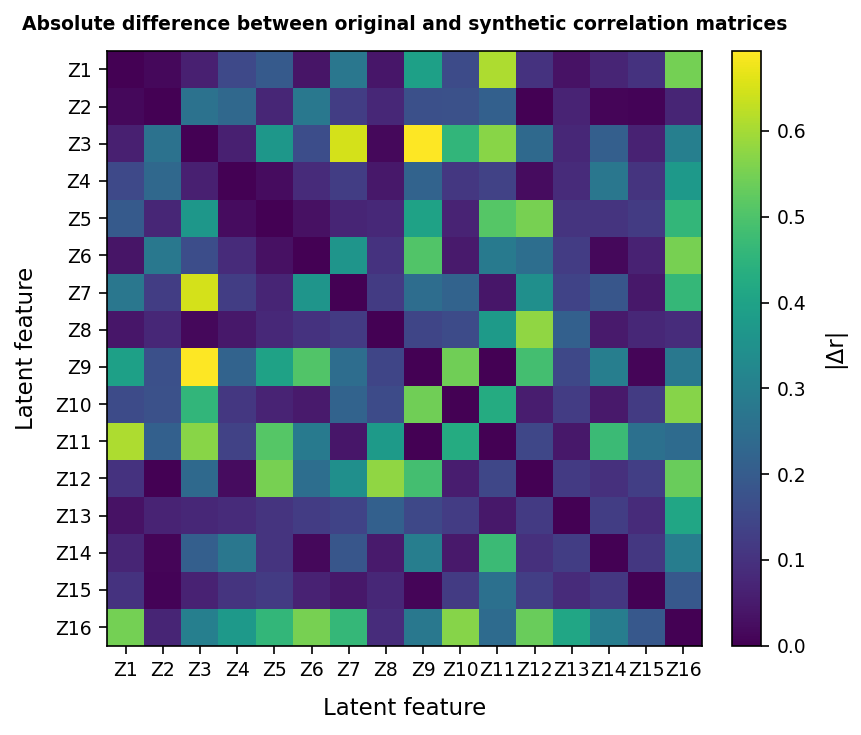

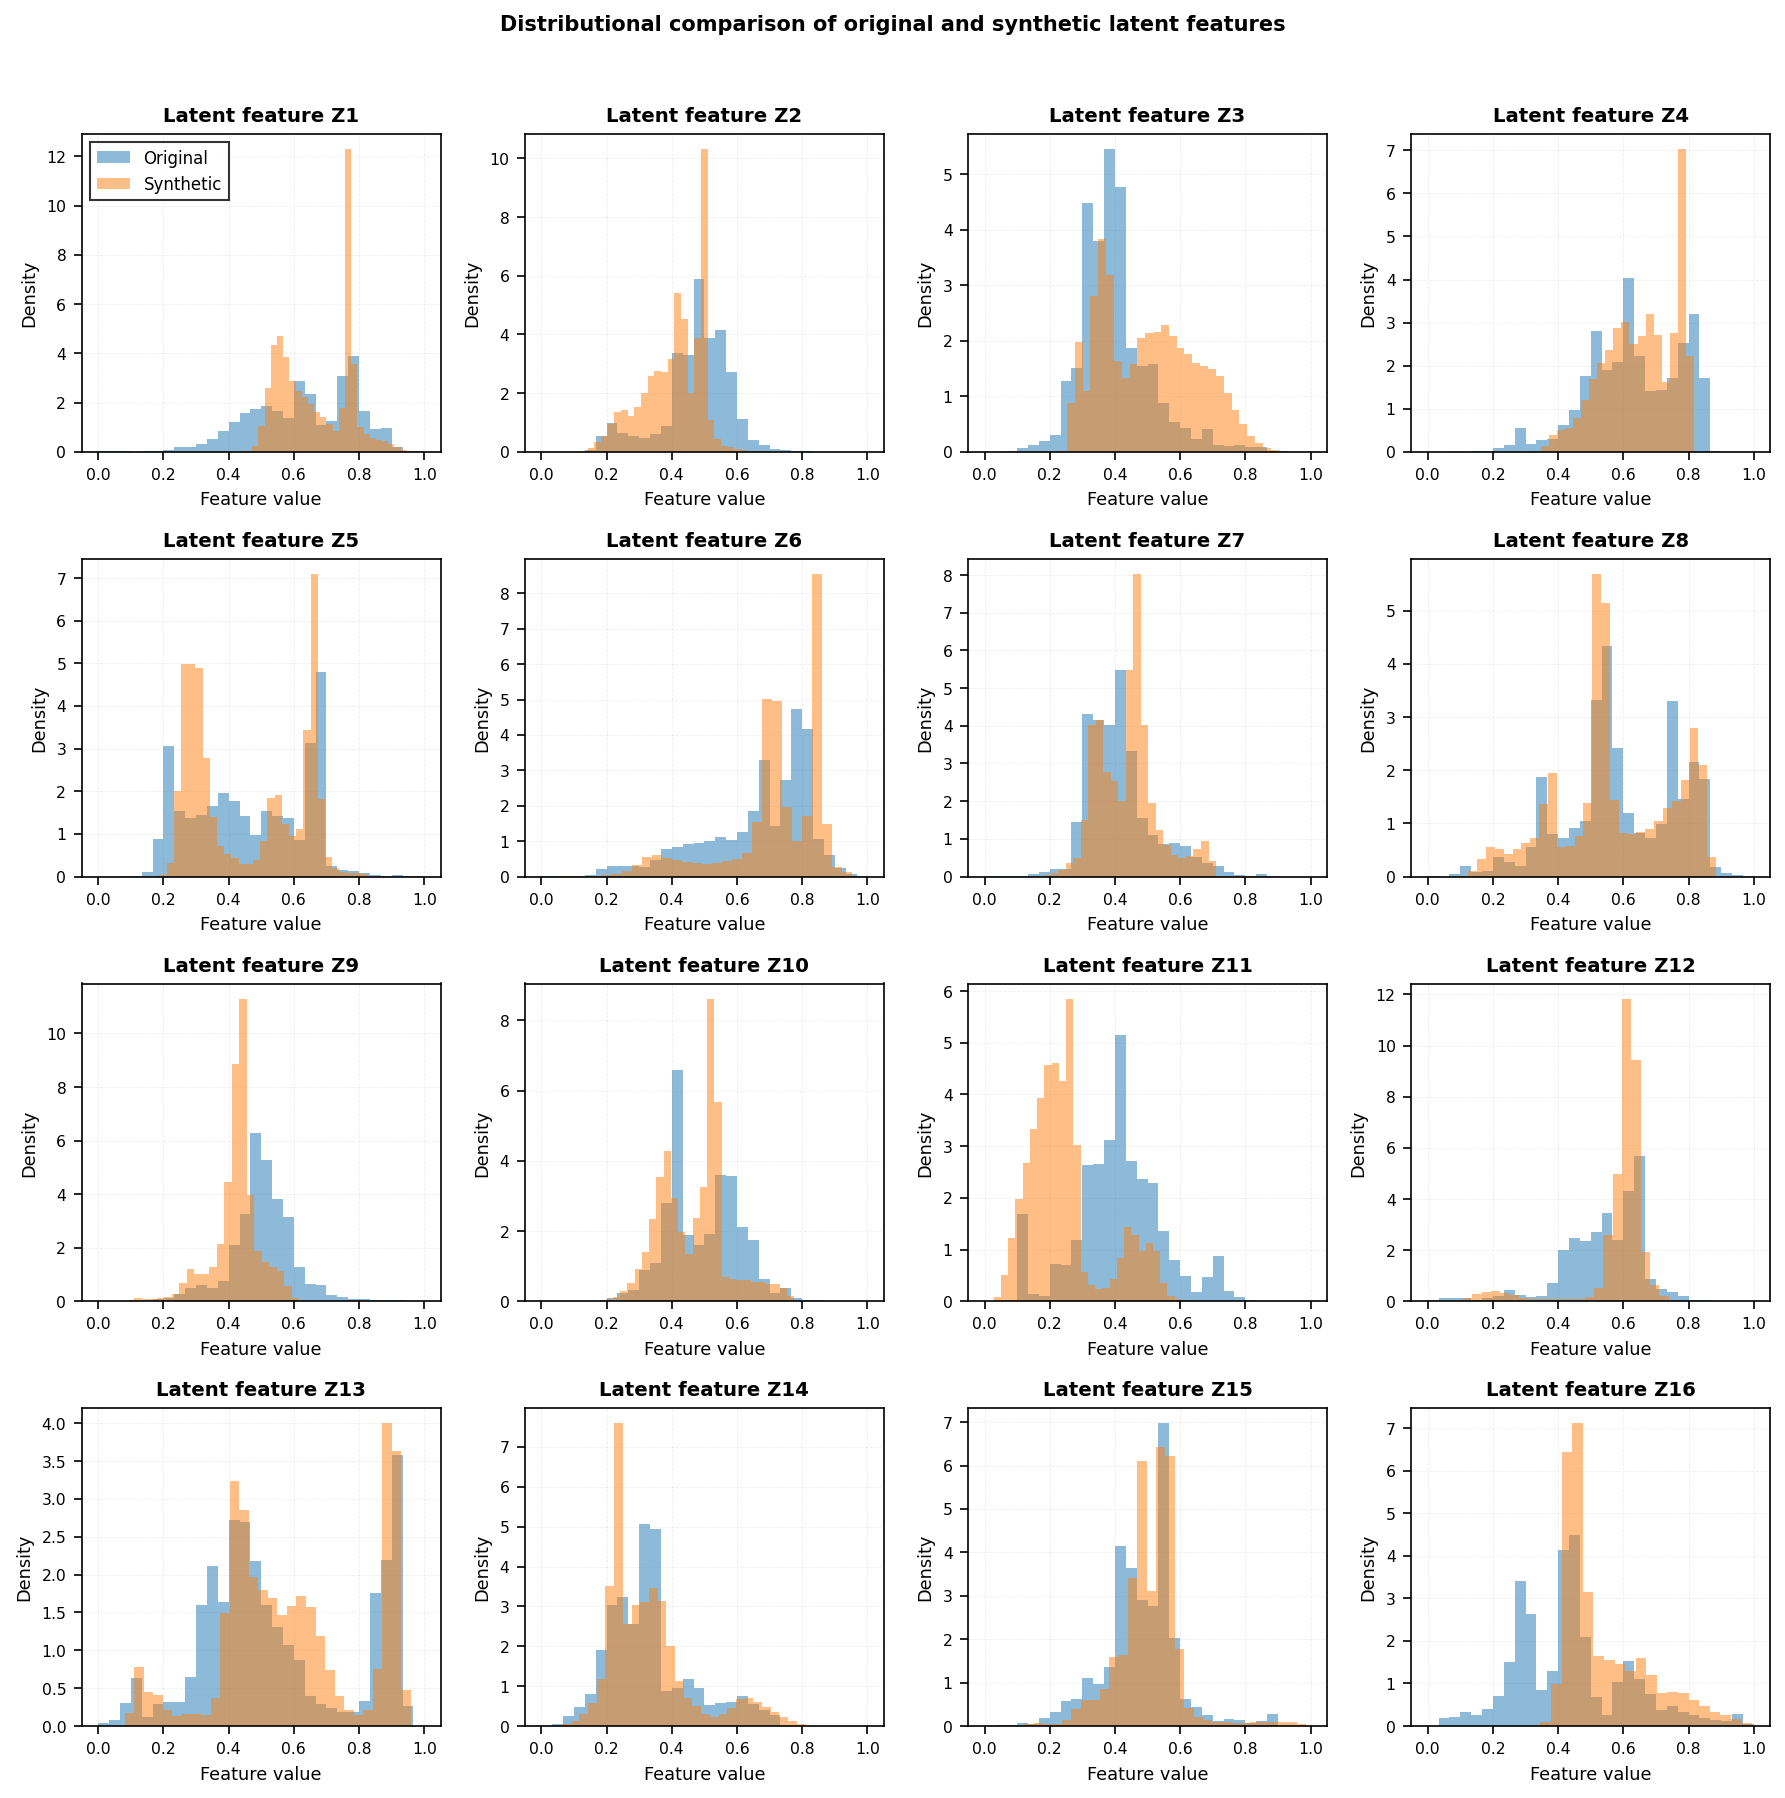

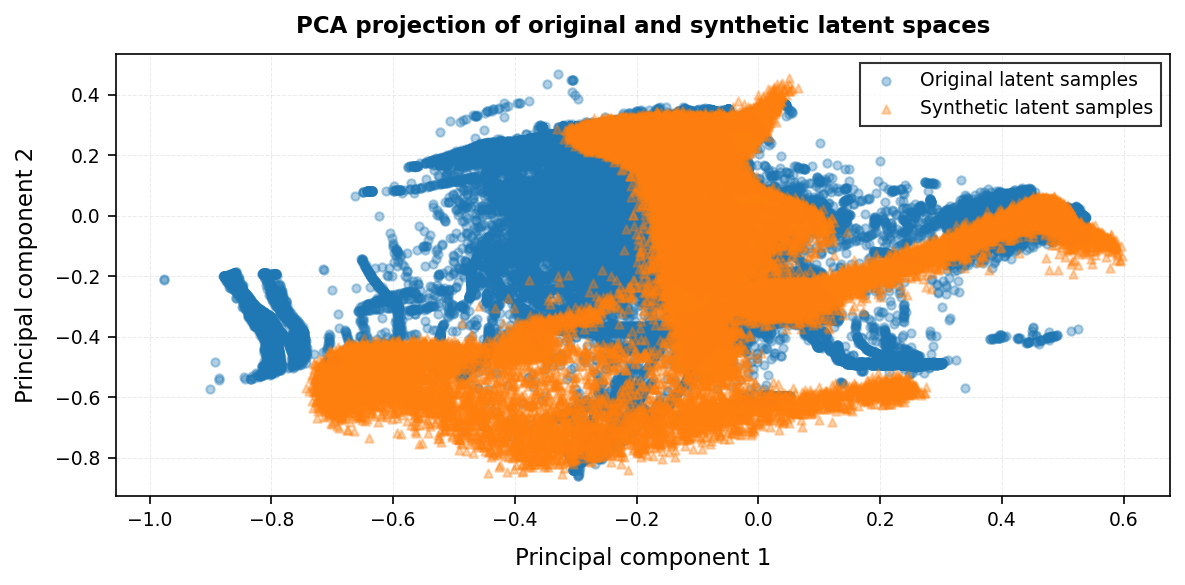

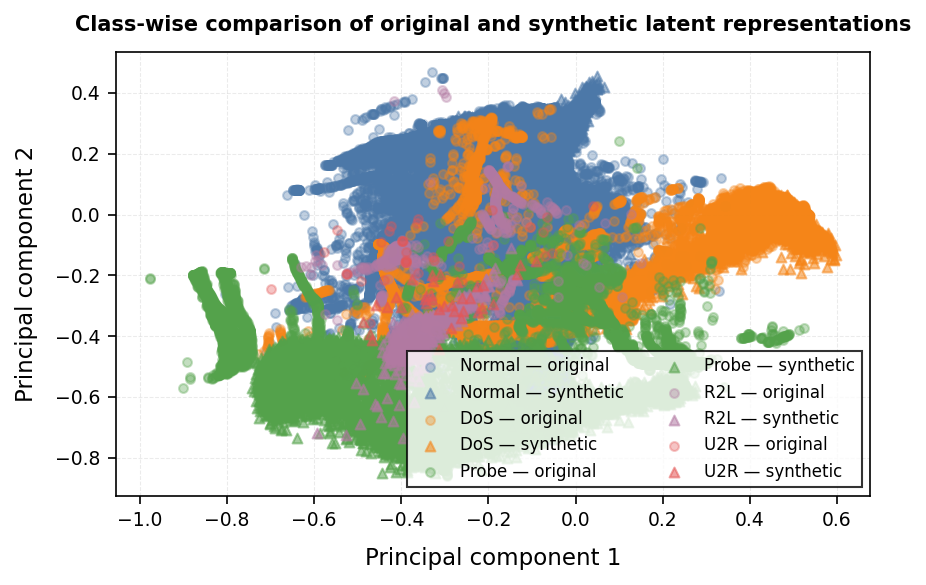

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.decomposition import PCA
from scipy.stats import pearsonr

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10,"axes.labelsize": 11, "axes.titlesize": 11,"xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.fontsize": 9, "axes.linewidth": 0.8,"figure.dpi": 150, "savefig.dpi": 600,"pdf.fonttype": 42, "ps.fonttype": 42})

FIG_DIR = Path("publication_figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save_publication_figure(fig, filename):
    fig.savefig(FIG_DIR / f"{filename}.tif", dpi=600, bbox_inches="tight", pad_inches=0.05, facecolor="white", edgecolor="white", pil_kwargs={"compression": "tiff_lzw"})
    fig.savefig(FIG_DIR / f"{filename}.pdf", bbox_inches="tight", pad_inches=0.05, facecolor="white", edgecolor="white")
    fig.savefig(FIG_DIR / f"{filename}.png", dpi=600, bbox_inches="tight", pad_inches=0.05, facecolor="white", edgecolor="white")
CLASS_COLORS = ["#4C78A8", "#F58518", "#54A24B", "#B279A2", "#E45756"]

G.eval()
synthetic_latent_list, synthetic_label_list = [], []
with torch.no_grad():
    for class_id in range(len(CLASS_NAMES)):
        n_generate = np.sum(y_train == class_id)
        y_syn = torch.full((n_generate,), class_id, dtype=torch.long, device=DEVICE)
        z_noise = torch.randn(n_generate, NOISE_DIM, device=DEVICE)
        z_fake = G(z_noise, y_syn)
        synthetic_latent_list.append(z_fake.cpu().numpy())
        synthetic_label_list.append(np.full(n_generate, class_id))
Z_synthetic = np.vstack(synthetic_latent_list)
y_synthetic = np.concatenate(synthetic_label_list)

original_corr = np.corrcoef(Z_train_n, rowvar=False)
synthetic_corr = np.corrcoef(Z_synthetic, rowvar=False)
correlation_difference = np.abs(original_corr - synthetic_corr)
off_diagonal_mask = ~np.eye(LATENT_DIM, dtype=bool)
original_corr_values = original_corr[off_diagonal_mask]
synthetic_corr_values = synthetic_corr[off_diagonal_mask]
difference_values = correlation_difference[off_diagonal_mask]
structure_r, structure_p = pearsonr(original_corr_values, synthetic_corr_values)
mean_difference = np.mean(difference_values)
median_difference = np.median(difference_values)
min_difference = np.min(difference_values)
max_difference = np.max(difference_values)

feature_labels = [f"Z{i}" for i in range(1, LATENT_DIM + 1)]
fig13, ax13 = plt.subplots(figsize=(6, 5))
im13 = ax13.imshow(correlation_difference, cmap="viridis", vmin=0, vmax=max(np.max(correlation_difference), 1e-6), aspect="equal")
ax13.set_xticks(np.arange(LATENT_DIM)); ax13.set_yticks(np.arange(LATENT_DIM))
ax13.set_xticklabels(feature_labels); ax13.set_yticklabels(feature_labels)
ax13.set_xlabel("Latent feature", labelpad=8); ax13.set_ylabel("Latent feature", labelpad=8)
ax13.set_title("Absolute difference between original and synthetic correlation matrices", fontsize=9, fontweight="bold", pad=10)
cbar13 = fig13.colorbar(im13, ax=ax13, fraction=0.046, pad=0.04); cbar13.set_label("|Δr|", rotation=90, labelpad=8)
fig13.tight_layout()
save_publication_figure(fig13, "Fig13_Correlation_Matrix_Difference")
plt.show(); plt.close(fig13)

n_cols = 4
n_rows = int(np.ceil(LATENT_DIM / n_cols))
fig14, axes14 = plt.subplots(n_rows, n_cols, figsize=(12, 3.0 * n_rows))
axes14 = np.asarray(axes14).flatten()
for i in range(LATENT_DIM):
    ax = axes14[i]
    ax.hist(Z_train_n[:, i], bins=30, density=True, alpha=0.50, label="Original")
    ax.hist(Z_synthetic[:, i], bins=30, density=True, alpha=0.50, label="Synthetic")
    ax.set_title(f"Latent feature Z{i+1}", fontsize=9.5, fontweight="bold")
    ax.set_xlabel("Feature value", fontsize=8.5); ax.set_ylabel("Density", fontsize=8.5)
    ax.tick_params(axis="both", labelsize=7.5); ax.grid(linestyle="--", linewidth=0.4, alpha=0.20)
    ax.set_axisbelow(True)
    if i == 0: ax.legend(frameon=True, edgecolor="black", fancybox=False, fontsize=8)

for i in range(LATENT_DIM, len(axes14)): axes14[i].axis("off")
fig14.suptitle("Distributional comparison of original and synthetic latent features", fontsize=10, fontweight="bold", y=0.995)
fig14.tight_layout(rect=[0, 0, 1, 0.98])
save_publication_figure(fig14, "Fig14_Original_Synthetic_Latent_Distributions")
plt.show(); plt.close(fig14)

Z_combined = np.vstack([Z_train_n, Z_synthetic])
pca = PCA(n_components=2, random_state=42)
Z_pca = pca.fit_transform(Z_combined)
n_original = len(Z_train_n)
Z_original_pca = Z_pca[:n_original]
Z_synthetic_pca = Z_pca[n_original:]
pc1_variance = pca.explained_variance_ratio_[0] * 100
pc2_variance = pca.explained_variance_ratio_[1] * 100

fig15, ax15 = plt.subplots(figsize=(8, 4))
ax15.scatter(Z_original_pca[:, 0], Z_original_pca[:, 1], s=16, alpha=0.35, marker="o", label="Original latent samples")
ax15.scatter(Z_synthetic_pca[:, 0], Z_synthetic_pca[:, 1], s=16, alpha=0.35, marker="^", label="Synthetic latent samples")
ax15.set_xlabel(f"Principal component 1", labelpad=8)
ax15.set_ylabel(f"Principal component 2", labelpad=8)
ax15.set_title("PCA projection of original and synthetic latent spaces", fontsize=11, fontweight="bold", pad=10)
ax15.grid(linestyle="--", linewidth=0.5, alpha=0.25); ax15.set_axisbelow(True)
ax15.legend(frameon=True, edgecolor="black", fancybox=False, loc="best")
fig15.tight_layout()
save_publication_figure(fig15, "Fig15_PCA_Original_vs_Synthetic_Latent")
plt.show(); plt.close(fig15)

fig16, ax16 = plt.subplots(figsize=(6, 4))
for class_id, class_name in enumerate(CLASS_NAMES):
    original_idx = y_train == class_id
    synthetic_idx = y_synthetic == class_id
    ax16.scatter(Z_original_pca[original_idx, 0], Z_original_pca[original_idx, 1], s=18, alpha=0.35, color=CLASS_COLORS[class_id], marker="o", label=f"{class_name} — original")
    ax16.scatter(Z_synthetic_pca[synthetic_idx, 0], Z_synthetic_pca[synthetic_idx, 1], s=22, alpha=0.55, color=CLASS_COLORS[class_id], marker="^", label=f"{class_name} — synthetic")
ax16.set_xlabel(f"Principal component 1", labelpad=8)
ax16.set_ylabel(f"Principal component 2", labelpad=8)
ax16.set_title("Class-wise comparison of original and synthetic latent representations", fontsize=10, fontweight="bold", pad=10)
ax16.grid(linestyle="--", linewidth=0.5, alpha=0.25); ax16.set_axisbelow(True)
ax16.legend(frameon=True, edgecolor="black", fancybox=False, fontsize=8, ncol=2, loc="best")
fig16.tight_layout()
save_publication_figure(fig16, "Fig16_Classwise_Original_Synthetic_Latent")
plt.show(); plt.close(fig16)

In [ ]:
G.eval()
TARGET_RATIO = 0.0980

class_counts = np.bincount(y_train, minlength=len(CLASS_NAMES))
minority_ids = [CLASS_NAMES.index("Probe"), CLASS_NAMES.index("R2L"), CLASS_NAMES.index("U2R")]
majority_ids = [i for i in range(len(CLASS_NAMES)) if i not in minority_ids]
majority_count = class_counts[majority_ids].sum()
final_total = int(np.ceil(majority_count / (1.0 - len(minority_ids) * TARGET_RATIO)))
target_minority_count = max(int(np.floor(TARGET_RATIO * final_total)), max(class_counts[i] for i in minority_ids))
final_total = majority_count + target_minority_count * len(minority_ids)


synthetic_data, synthetic_labels = [], []
print("\n" + "=" * 65)
print("SYNTHETIC SAMPLE GENERATION")
print("=" * 65)

for class_id in minority_ids:
    n_generate = max(0, target_minority_count - class_counts[class_id])
    print(f"{CLASS_NAMES[class_id]:12s}: Original = {class_counts[class_id]:,} | Target = {target_minority_count:,} | Generate = {n_generate:,}")
    if n_generate == 0:
        continue

    batches = []
    with torch.no_grad():
        for start in range(0, n_generate, GAN_BATCH):
            bs = min(GAN_BATCH, n_generate - start)
            noise = torch.randn(bs, NOISE_DIM, device=DEVICE)
            labels = torch.full((bs,), class_id, dtype=torch.long, device=DEVICE)
            batches.append(G(noise, labels).cpu().numpy())

    fake_data = np.concatenate(batches, axis=0)[:n_generate]
    synthetic_data.append(fake_data.astype(np.float32))
    synthetic_labels.append(np.full(n_generate, class_id, dtype=np.int64))

if synthetic_data:
    Z_synthetic = np.concatenate(synthetic_data, axis=0).astype(np.float32)
    y_synthetic = np.concatenate(synthetic_labels, axis=0).astype(np.int64)
else:
    Z_synthetic = np.empty((0, Z_train_n.shape[1]), dtype=np.float32)
    y_synthetic = np.empty((0,), dtype=np.int64)

Z_train_balanced = np.concatenate([Z_train_n, Z_synthetic], axis=0)
y_train_balanced = np.concatenate([y_train, y_synthetic], axis=0)

rng = np.random.default_rng(SEED)
idx = rng.permutation(len(y_train_balanced))
Z_train_balanced = Z_train_balanced[idx]
y_train_balanced = y_train_balanced[idx]

final_counts = np.bincount(y_train_balanced, minlength=len(CLASS_NAMES))
final_total_actual = len(y_train_balanced)
final_percent = final_counts / final_total_actual * 100

print(f"\nOriginal training shape : {Z_train_n.shape}")
print(f"Synthetic data shape    : {Z_synthetic.shape}")
print(f"Balanced training shape : {Z_train_balanced.shape}")


SYNTHETIC SAMPLE GENERATION
Probe       : Original = 8,112 | Target = 11,016 | Generate = 2,904
R2L         : Original = 668 | Target = 11,016 | Generate = 10,348
U2R         : Original = 35 | Target = 11,016 | Generate = 10,981

Original training shape : (88176, 16)
Synthetic data shape    : (24233, 16)
Balanced training shape : (112409, 16)


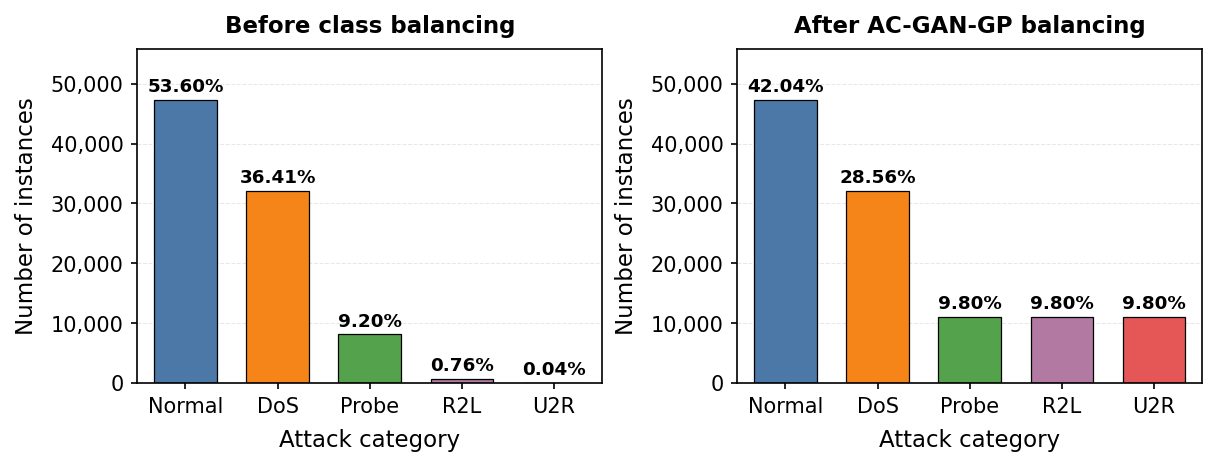

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from pathlib import Path
plt.rcParams.update({"font.family":"DejaVu Sans","font.size":10,"axes.labelsize":11,"axes.titlesize":12,"xtick.labelsize":10,"ytick.labelsize":10,"axes.linewidth":0.8,"xtick.major.width":0.8,"ytick.major.width":0.8,"figure.dpi":150,"savefig.dpi":600,"pdf.fonttype":42,"ps.fonttype":42})
original_counts = pd.Series(y_train).value_counts().reindex(range(len(CLASS_NAMES)),fill_value=0)
original_counts.index = CLASS_NAMES
original_percent = original_counts / original_counts.sum() * 100
balanced_counts = pd.Series(y_train_balanced).value_counts().reindex(range(len(CLASS_NAMES)),fill_value=0)
balanced_counts.index = CLASS_NAMES
balanced_percent = balanced_counts / balanced_counts.sum() * 100
colors = ["#4C78A8","#F58518","#54A24B","#B279A2","#E45756"]
fig,axes = plt.subplots(1,2,figsize=(8,3),constrained_layout=True)

def plot_distribution(ax,counts,percentages,panel_label,panel_title):
    x = np.arange(len(CLASS_NAMES))
    bars = ax.bar(x,counts.values,width=0.68,color=colors,edgecolor="black",linewidth=0.6)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda x,pos:f"{int(x):,}"))
    ax.grid(axis="y",linestyle="--",linewidth=0.5,alpha=0.30)
    ax.set_axisbelow(True)
    ax.set_xticks(x)
    ax.set_xticklabels(CLASS_NAMES)
    ax.set_xlabel("Attack category",labelpad=6)
    ax.set_ylabel("Number of instances",labelpad=6)
    ax.set_title(panel_title,fontsize=11,fontweight="bold",pad=8)
    ax.text(-0.12,1.04,panel_label,transform=ax.transAxes,fontsize=12,fontweight="bold",va="bottom",ha="left")
    max_count = counts.max()
    for bar,pct in zip(bars,percentages.values):
        ax.text(bar.get_x()+bar.get_width()/2,bar.get_height()+max_count*0.015,f"{pct:.2f}%",ha="center",va="bottom",fontsize=8.8,fontweight="bold")
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.8)
        spine.set_color("black")
    ax.tick_params(axis="both",width=0.8,length=3)
    ax.margins(x=0.04)
    ax.set_ylim(0,max_count*1.18)

plot_distribution(axes[0],original_counts,original_percent,"","Before class balancing")
plot_distribution(axes[1],balanced_counts,balanced_percent,"","After AC-GAN-GP balancing")

fig.patch.set_facecolor("white")
output_dir = Path("publication_figures")
output_dir.mkdir(parents=True,exist_ok=True)
fig.savefig(output_dir/"Fig1_ACGAN_GP_Class_Distribution.tif",dpi=600,format="tiff",bbox_inches="tight",pad_inches=0.05,facecolor="white",pil_kwargs={"compression":"tiff_lzw"})
fig.savefig(output_dir/"Fig1_ACGAN_GP_Class_Distribution.pdf",format="pdf",bbox_inches="tight",pad_inches=0.05,facecolor="white")
fig.savefig(output_dir/"Fig1_ACGAN_GP_Class_Distribution.png",dpi=600,format="png",bbox_inches="tight",pad_inches=0.05,facecolor="white")
plt.show()

In [ ]:
models = OrderedDict([
    ("LR", LogisticRegression(max_iter=500, solver="lbfgs", random_state=SEED)),
    ("KNN", KNeighborsClassifier(n_neighbors=5, n_jobs=-1)),
    ("RF", RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)),
    ("GB", GradientBoostingClassifier(n_estimators=200, random_state=SEED)),
    ("Extra Trees", ExtraTreesClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)),
    ("XGBoost", xgb.XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,subsample=0.9, colsample_bytree=0.9,objective="multi:softprob", num_class=5,eval_metric="mlogloss", tree_method="hist",random_state=SEED, n_jobs=-1)),
    ("LightGBM", lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31,objective="multiclass", num_class=5,random_state=SEED, n_jobs=-1, verbosity=-1)),
    ("HGBoosting", HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, random_state=SEED))])


LR

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal     0.9414    0.9646    0.9529     20083
         DoS     0.9762    0.9543    0.9651     13825
       Probe     0.8724    0.8672    0.8698      3540
         R2L     0.6910    0.3761    0.4871       327
         U2R     0.5000    0.0588    0.1053        17

    accuracy                         0.9462     37792
   macro avg     0.7962    0.6442    0.6760     37792
weighted avg     0.9453    0.9462    0.9452     37792



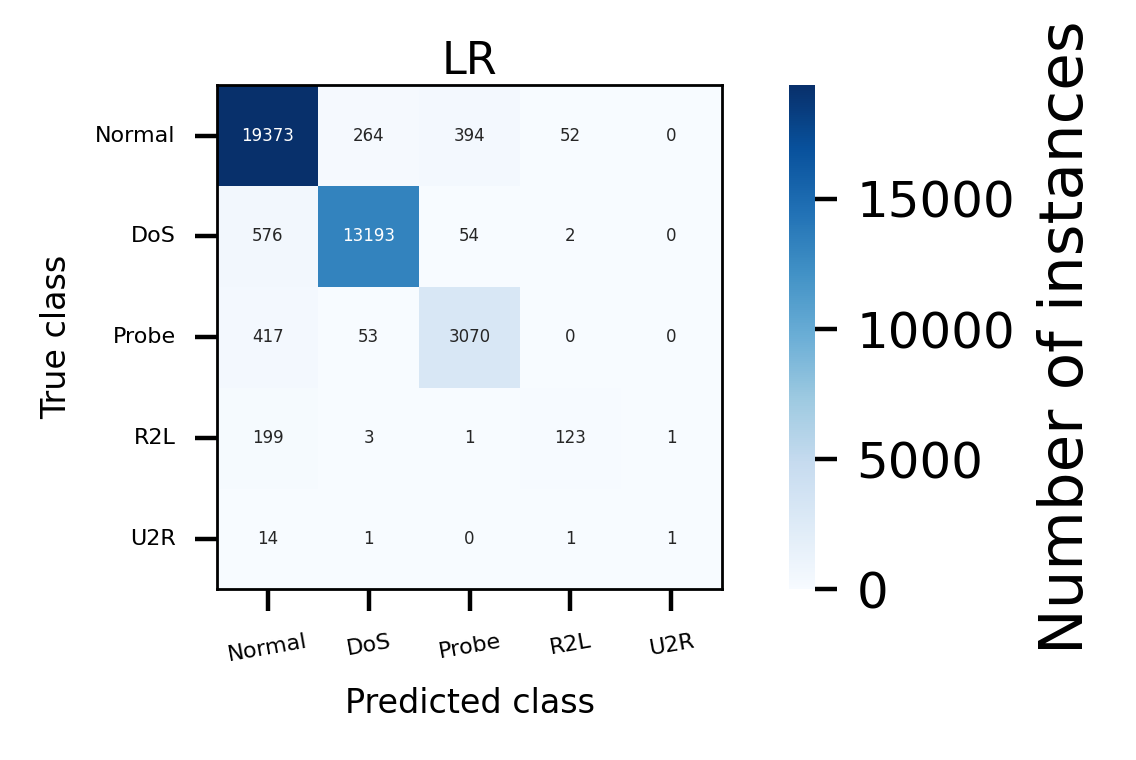


KNN

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal     0.9941    0.9953    0.9947     20083
         DoS     0.9962    0.9981    0.9972     13825
       Probe     0.9926    0.9814    0.9869      3540
         R2L     0.9231    0.9174    0.9202       327
         U2R     0.7500    0.3529    0.4800        17

    accuracy                         0.9941     37792
   macro avg     0.9312    0.8490    0.8758     37792
weighted avg     0.9940    0.9941    0.9940     37792



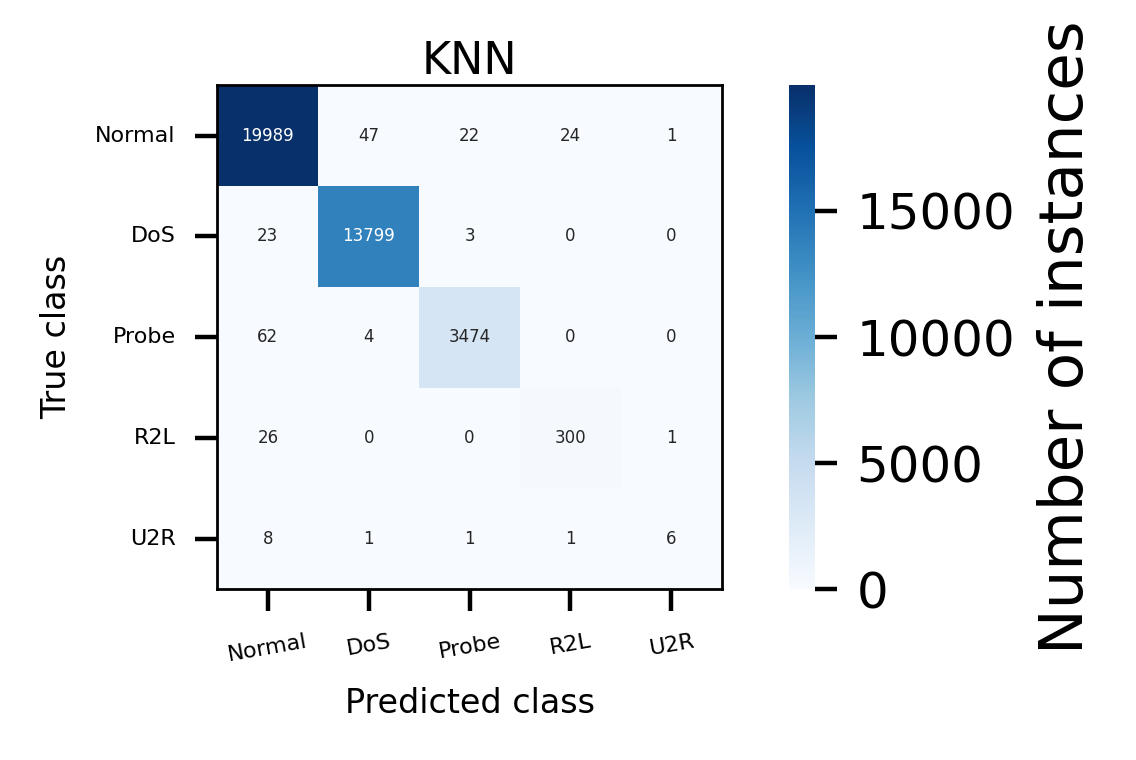


RF

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal     0.9941    0.9978    0.9959     20083
         DoS     0.9985    0.9975    0.9980     13825
       Probe     0.9966    0.9856    0.9911      3540
         R2L     0.9522    0.9144    0.9329       327
         U2R     0.6000    0.3529    0.4444        17

    accuracy                         0.9955     37792
   macro avg     0.9083    0.8496    0.8725     37792
weighted avg     0.9954    0.9955    0.9954     37792



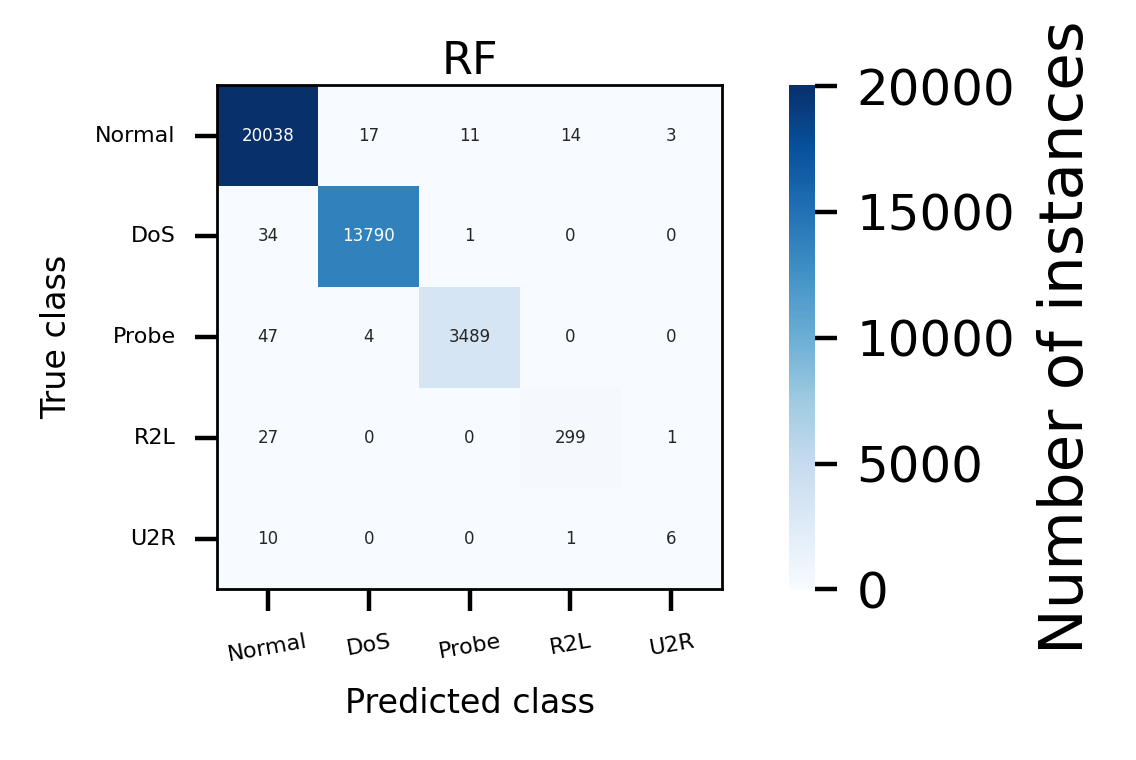


GB

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal     0.9891    0.9959    0.9925     20083
         DoS     0.9977    0.9933    0.9955     13825
       Probe     0.9875    0.9780    0.9827      3540
         R2L     0.9298    0.8104    0.8660       327
         U2R     0.4667    0.4118    0.4375        17

    accuracy                         0.9914     37792
   macro avg     0.8741    0.8379    0.8548     37792
weighted avg     0.9913    0.9914    0.9913     37792



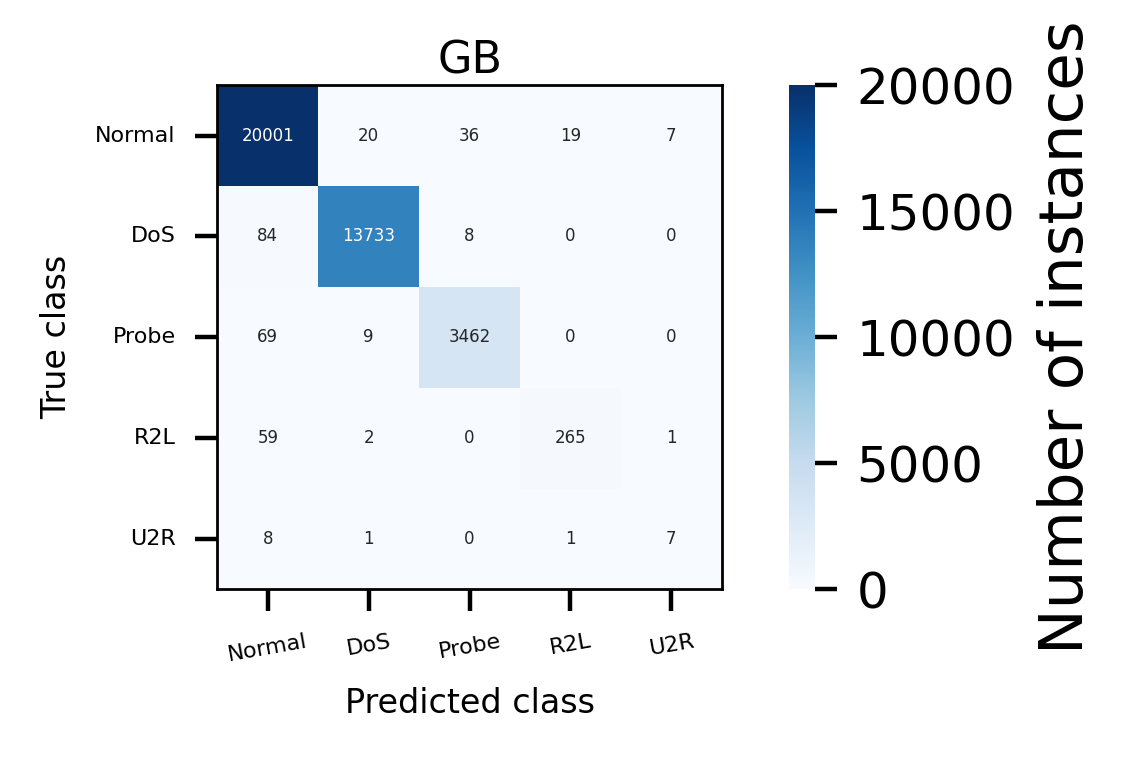


Extra Trees

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal     0.9947    0.9981    0.9964     20083
         DoS     0.9990    0.9982    0.9986     13825
       Probe     0.9977    0.9862    0.9919      3540
         R2L     0.9498    0.9266    0.9381       327
         U2R     0.6000    0.3529    0.4444        17

    accuracy                         0.9961     37792
   macro avg     0.9083    0.8524    0.8739     37792
weighted avg     0.9960    0.9961    0.9960     37792



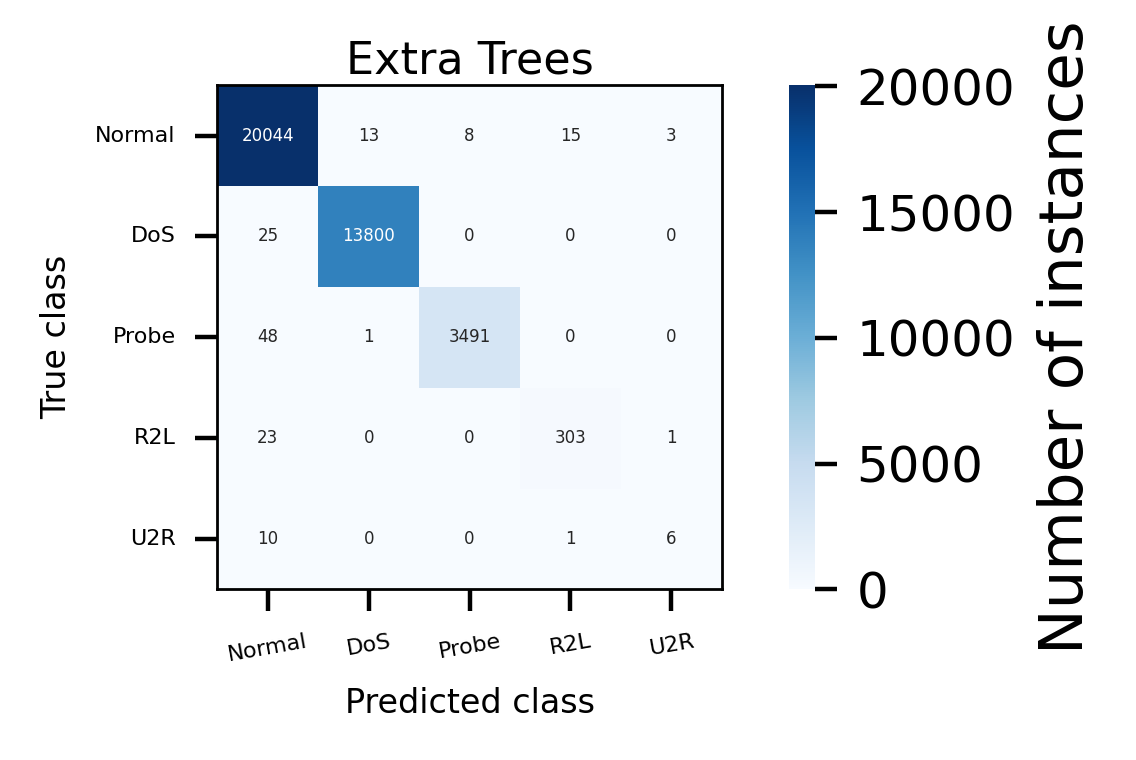


XGBoost

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal     0.9952    0.9975    0.9963     20083
         DoS     0.9983    0.9980    0.9982     13825
       Probe     0.9960    0.9884    0.9922      3540
         R2L     0.9470    0.9297    0.9383       327
         U2R     0.6000    0.3529    0.4444        17

    accuracy                         0.9959     37792
   macro avg     0.9073    0.8533    0.8739     37792
weighted avg     0.9958    0.9959    0.9959     37792



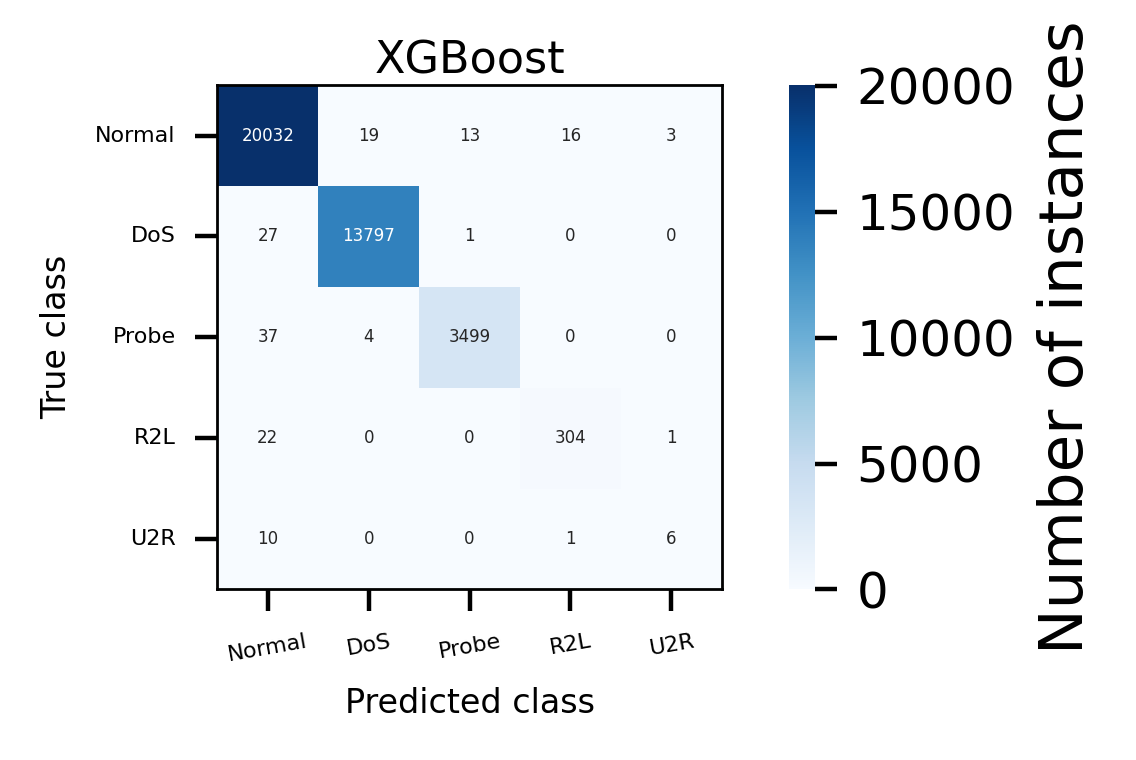


LightGBM

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal     0.9952    0.9976    0.9964     20083
         DoS     0.9986    0.9982    0.9984     13825
       Probe     0.9960    0.9879    0.9919      3540
         R2L     0.9497    0.9235    0.9364       327
         U2R     0.6364    0.4118    0.5000        17

    accuracy                         0.9960     37792
   macro avg     0.9152    0.8638    0.8846     37792
weighted avg     0.9959    0.9960    0.9960     37792



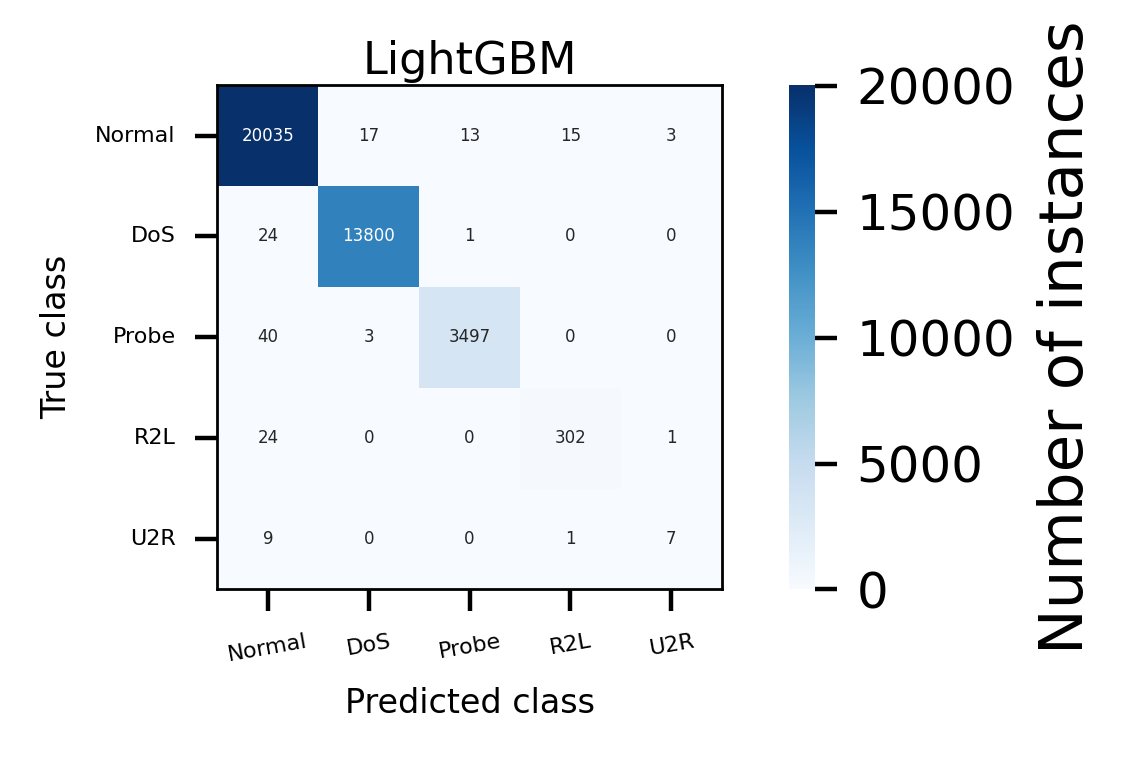


HGBoosting

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal     0.9947    0.9976    0.9961     20083
         DoS     0.9985    0.9981    0.9983     13825
       Probe     0.9963    0.9859    0.9911      3540
         R2L     0.9436    0.9205    0.9319       327
         U2R     0.7500    0.3529    0.4800        17

    accuracy                         0.9957     37792
   macro avg     0.9366    0.8510    0.8795     37792
weighted avg     0.9957    0.9957    0.9957     37792



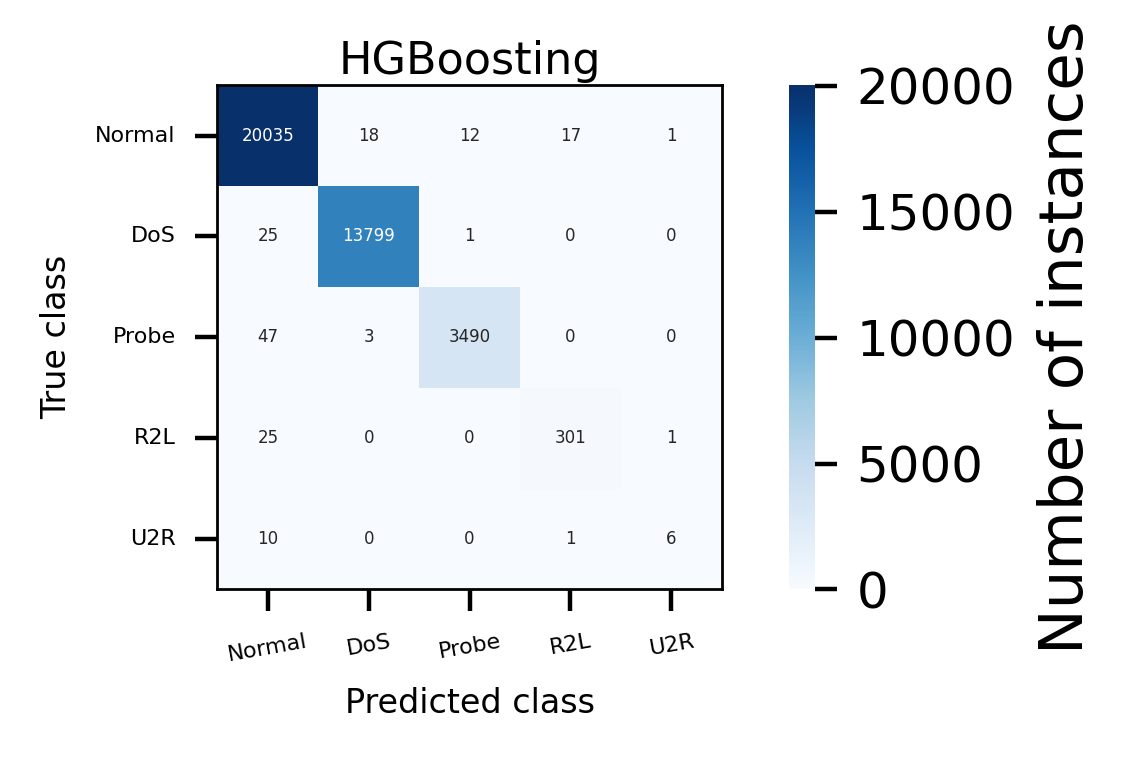


FINAL CLASSIFIER COMPARISON
      Model  Accuracy  Macro Precision  Macro Recall  Macro F1  Macro AUC
   LightGBM  0.996004         0.915159      0.863793  0.884623   0.997248
 HGBoosting  0.995740         0.936606      0.851007  0.879478   0.997410
        KNN  0.994073         0.931195      0.849033  0.875812   0.966613
    XGBoost  0.995925         0.907324      0.853292  0.873883   0.998110
Extra Trees  0.996084         0.908257      0.852391  0.873882   0.967866
         RF  0.995502         0.908285      0.849627  0.872467   0.969096
         GB  0.991427         0.874147      0.837878  0.854842   0.992486
         LR  0.946232         0.796212      0.644227  0.676045   0.977068


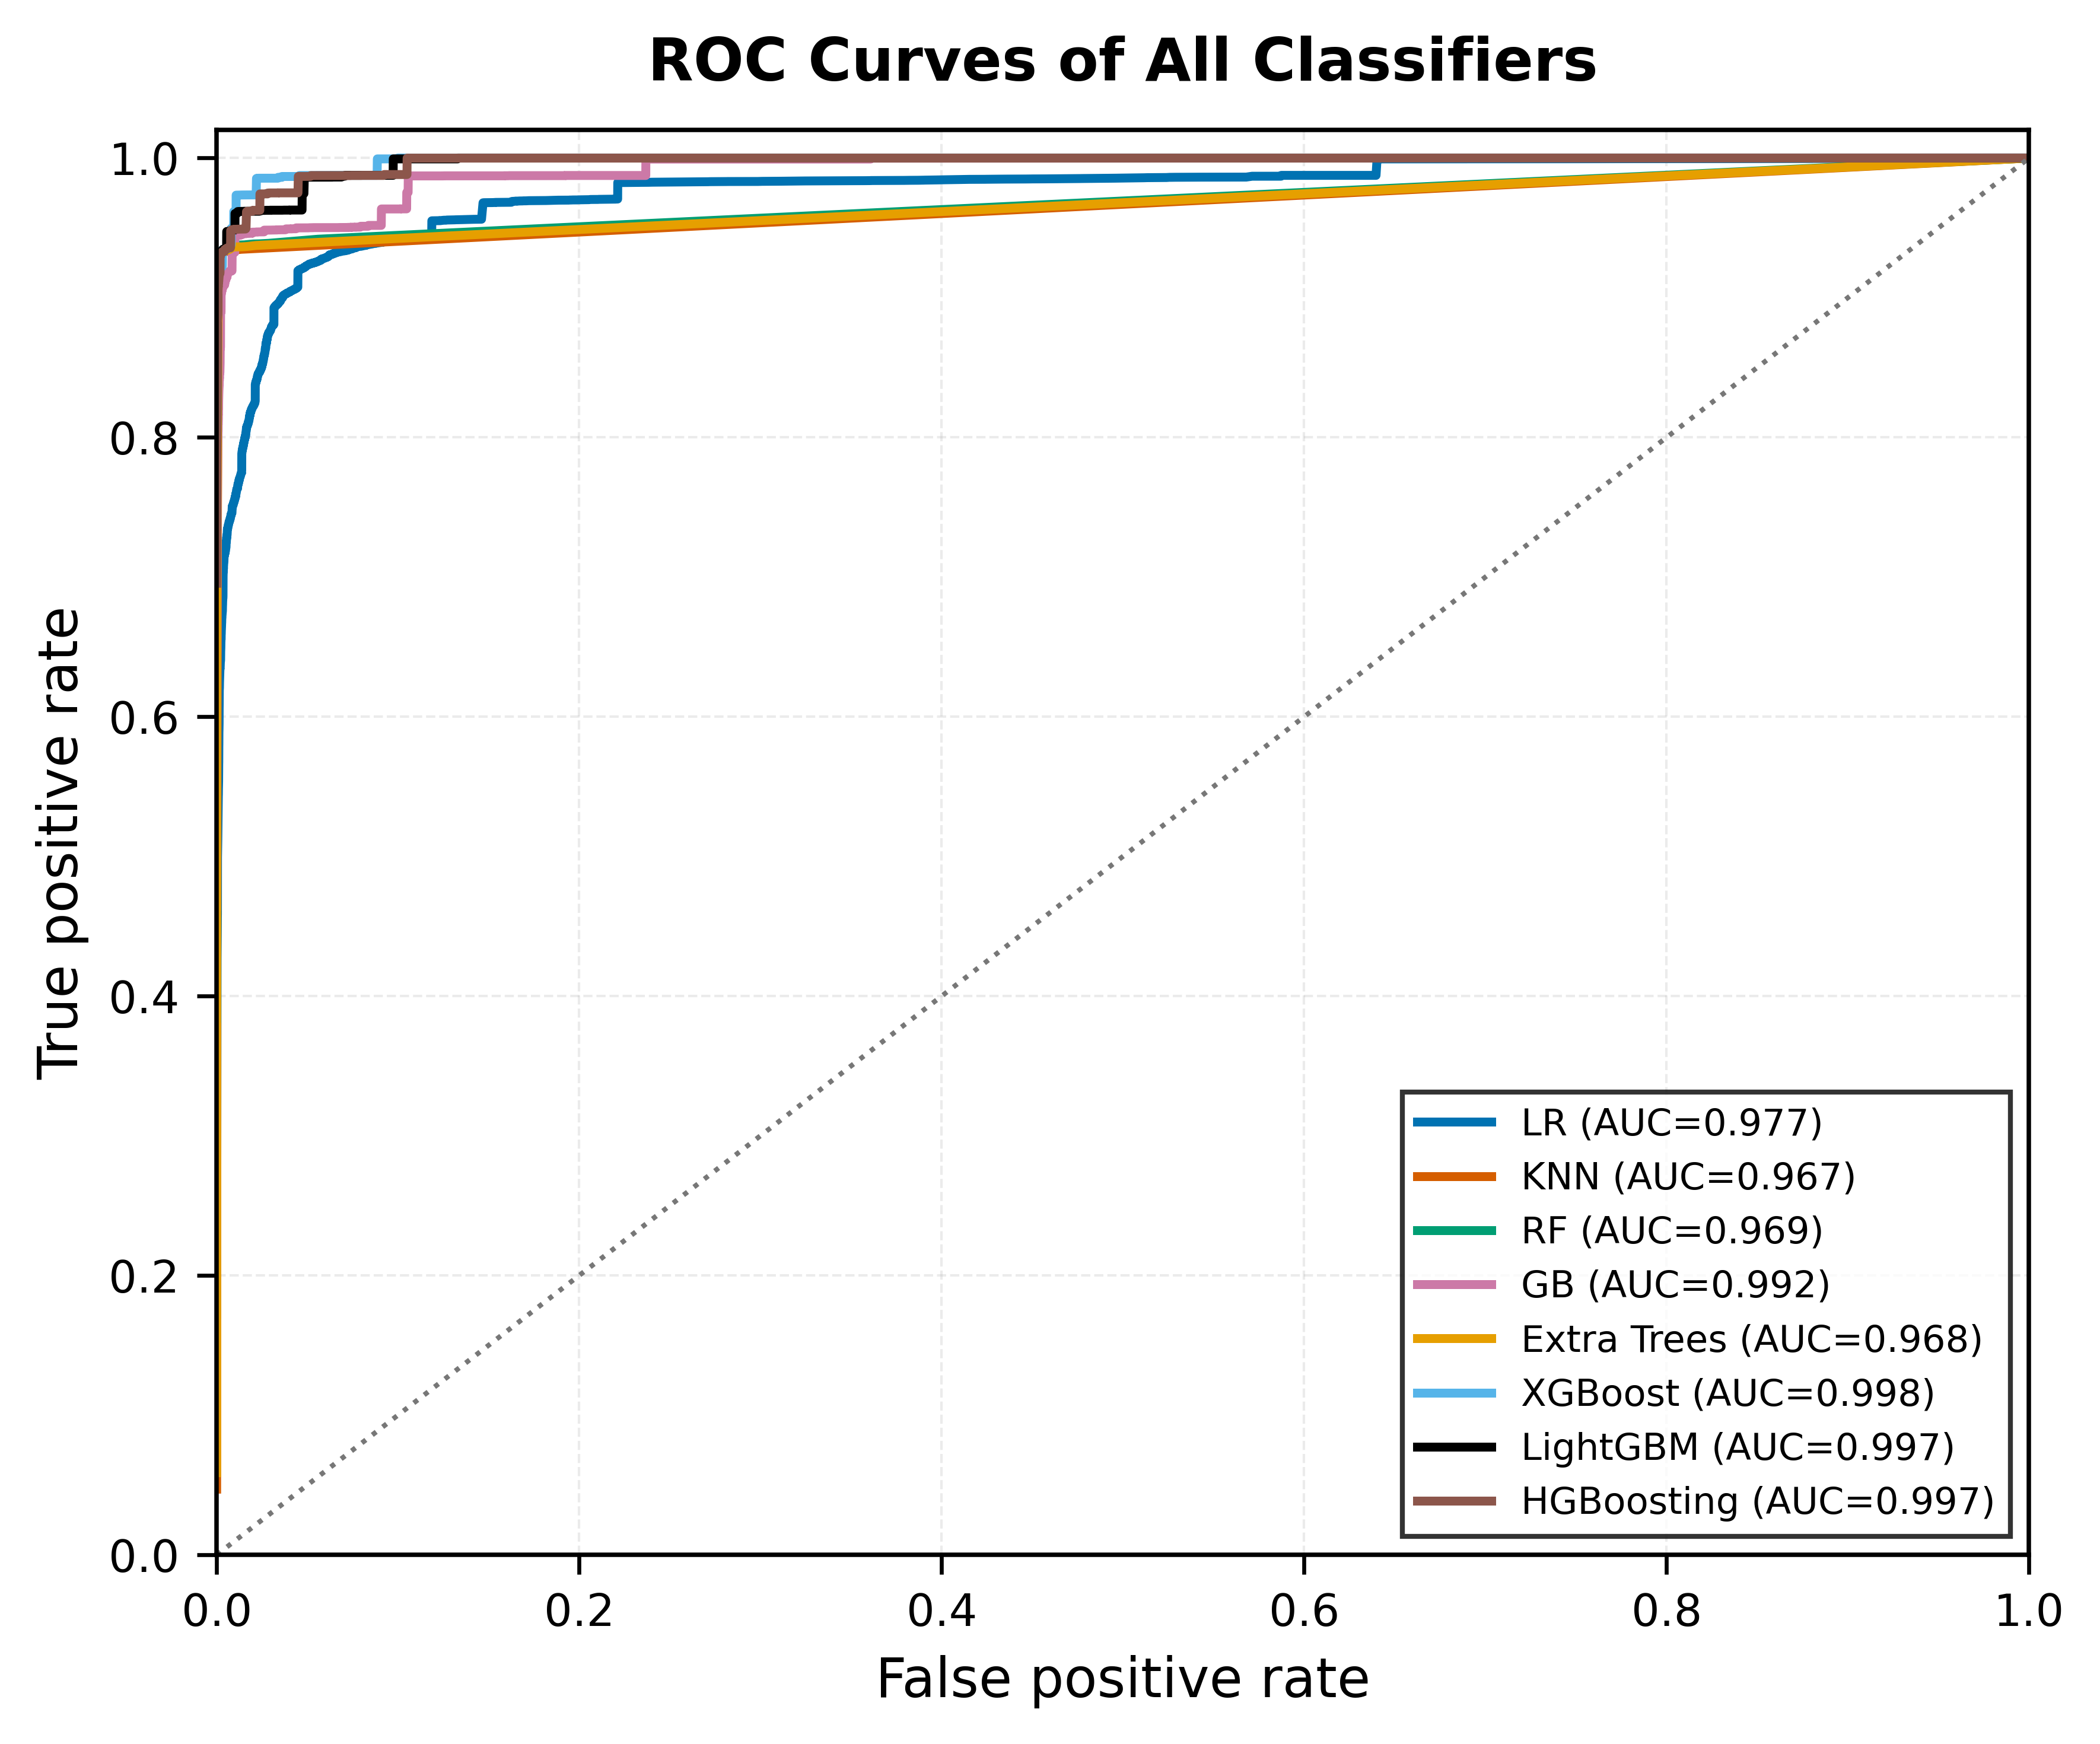

In [ ]:
# ============================================================
# CLASSIFICATION REPORT + CONFUSION MATRICES + COMBINED ROC CURVE FOR ALL CLASSIFIERS
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc
from sklearn.preprocessing import label_binarize

CLASS_NAMES = ["Normal", "DoS", "Probe", "R2L", "U2R"]
RESULT_DIR = "balanced_classifier_results"
os.makedirs(RESULT_DIR, exist_ok=True)
y_test_bin = label_binarize(y_test, classes=np.arange(len(CLASS_NAMES)))
results = []
all_classifier_roc = {}
ae.eval()
with torch.no_grad():
    Z_test = ae.encoder(torch.from_numpy(X_test.astype(np.float32)).to(DEVICE)).cpu().numpy().astype(np.float32)
Z_test_n = latent_scaler.transform(Z_test).astype(np.float32)

for model_name, model in models.items():
    print("\n" + "=" * 80)
    print(model_name)
    print("=" * 80)
    model.fit(Z_train_balanced, y_train_balanced)
    y_pred = model.predict(Z_test_n)
    y_prob = model.predict_proba(Z_test_n)
    report = classification_report(y_test, y_pred, labels=np.arange(len(CLASS_NAMES)), target_names=CLASS_NAMES, digits=4, zero_division=0)
    print("\nCLASSIFICATION REPORT")
    print(report)
    safe_name = model_name.replace(" ", "_")
    with open(os.path.join(RESULT_DIR, f"{safe_name}_classification_report.txt"), "w") as f:
        f.write(report)
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average="macro", zero_division=0)
    recall = recall_score(y_test, y_pred, average="macro", zero_division=0)
    f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)

    # ========================================================
    # CONFUSION MATRIX
    # ========================================================
    cm = confusion_matrix(y_test, y_pred, labels=np.arange(len(CLASS_NAMES)))
    fig, ax = plt.subplots(figsize=(4, 2), dpi=400)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", square=True, linewidths=0, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cbar_kws={"label": "Number of instances"}, annot_kws={"fontsize": 3}, ax=ax)
    ax.set_xlabel("Predicted class", fontsize=6)
    ax.set_ylabel("True class", fontsize=6)
    ax.set_title(model_name, fontsize=8, pad=2)
    ax.tick_params(axis="x", labelrotation=10, labelsize=4)
    ax.tick_params(axis="y", labelrotation=0, labelsize=4)
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.5)
        spine.set_color("black")
    plt.tight_layout()
    fig.savefig(os.path.join(RESULT_DIR, f"{safe_name}_confusion_matrix.tif"), dpi=400, format="tiff", bbox_inches="tight", pad_inches=0.03, pil_kwargs={"compression": "tiff_lzw"})
    fig.savefig(os.path.join(RESULT_DIR, f"{safe_name}_confusion_matrix.pdf"), format="pdf", bbox_inches="tight", pad_inches=0.03)
    plt.show()
    plt.close(fig)
    pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(os.path.join(RESULT_DIR, f"{safe_name}_confusion_matrix.csv"))

    fpr, tpr = {}, {}
    for i in range(len(CLASS_NAMES)):
        fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
    all_fpr = np.unique(np.concatenate([fpr[i] for i in range(len(CLASS_NAMES))]))
    mean_tpr = np.zeros_like(all_fpr)
    for i in range(len(CLASS_NAMES)):
        mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
    mean_tpr /= len(CLASS_NAMES)
    macro_auc = auc(all_fpr, mean_tpr)
    all_classifier_roc[model_name] = {"fpr": all_fpr, "tpr": mean_tpr, "auc": macro_auc}
    results.append({"Model": model_name, "Accuracy": accuracy, "Macro Precision": precision, "Macro Recall": recall, "Macro F1": f1, "Macro AUC": macro_auc})

# ============================================================
# FINAL CLASSIFIER COMPARISON
# ============================================================
results_df = pd.DataFrame(results).sort_values("Macro F1", ascending=False).reset_index(drop=True)
print("\n" + "=" * 90)
print("FINAL CLASSIFIER COMPARISON")
print("=" * 90)
print(results_df.to_string(index=False))
results_df.to_csv(os.path.join(RESULT_DIR, "all_classifier_results.csv"), index=False)

# ============================================================
#ROC CURVE FOR ALL CLASSIFIERS
# ============================================================
fig, ax = plt.subplots(figsize=(6, 5), dpi=600)
classifier_colors = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#000000", "#8C564B", "#9467BD", "#17BECF"]
for idx, (model_name, roc_info) in enumerate(all_classifier_roc.items()):
    ax.plot(roc_info["fpr"], roc_info["tpr"], color=classifier_colors[idx % len(classifier_colors)], linewidth=1.8, label=f"{model_name} (AUC={roc_info['auc']:.3f})")
ax.plot([0, 1], [0, 1], color="#777777", linewidth=1, linestyle=":")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.set_xlabel("False positive rate", fontsize=11)
ax.set_ylabel("True positive rate", fontsize=11)
ax.set_title("ROC Curves of All Classifiers", fontsize=12, fontweight="bold", pad=10)
ax.legend(loc="lower right", fontsize=7.5, frameon=True, edgecolor="black", fancybox=False)
ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.25)
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(0.9)
    spine.set_color("black")
plt.tight_layout()
fig.savefig(os.path.join(RESULT_DIR, "ALL_CLASSIFIERS_ROC_AUC.tif"), dpi=600, format="tiff", bbox_inches="tight", pad_inches=0.05, pil_kwargs={"compression": "tiff_lzw"})
fig.savefig(os.path.join(RESULT_DIR, "ALL_CLASSIFIERS_ROC_AUC.pdf"), format="pdf", bbox_inches="tight", pad_inches=0.05)
fig.savefig(os.path.join(RESULT_DIR, "ALL_CLASSIFIERS_ROC_AUC.png"), dpi=600, format="png", bbox_inches="tight", pad_inches=0.05)
plt.show()
plt.close(fig)

# Statistical analysis

In [ ]:
# ================================================================
#  REPEATED AE → ACGAN-GP → CLASSIFIERS + Median/IQR + Wilcoxon + Holm correction
# ================================================================

from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, roc_auc_score)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,HistGradientBoostingClassifier)
import random, time, numpy as np, pandas as pd, torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from collections import OrderedDict
import xgboost as xgb
import lightgbm as lgb

# -------------------- SETTINGS --------------------
REPEAT_SEEDS = [42, 52, 62, 72, 92, 102, 112, 122, 132, 152, 162, 172, 182, 192, 202, 212, 222, 232, 242, 252]
ALPHA = 0.05
LATENT_DIM = 16
AE_BATCH = 32
NOISE_DIM = 100
GAN_EPOCHS = 20
GAN_BATCH = 128
GAN_LR = 2e-4
GP_LAMBDA = 10.0
CLS_WEIGHT = 1.0

CLASS_NAMES = ["normal", "dos", "probe", "r2l", "u2r"]
def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def run_ae(Xtr, Xte, seed):
    seed_everything(seed)
    ae = Autoencoder(input_dim=Xtr.shape[1],latent_dim=LATENT_DIM).to(DEVICE)
    opt = torch.optim.Adam(ae.parameters(), lr=AE_LR)
    loss_fn = nn.MSELoss()
    loader = DataLoader(TensorDataset(torch.from_numpy(Xtr).float()),batch_size=AE_BATCH, shuffle=True,pin_memory=torch.cuda.is_available())
    for _ in range(AE_EPOCHS):
        ae.train()
        for (xb,) in loader:
            xb = xb.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            xhat, _ = ae(xb)
            loss = loss_fn(xhat, xb)
            loss.backward()
            opt.step()

    ae.eval()
    with torch.no_grad():
        Ztr = ae.encoder(torch.from_numpy(Xtr).float().to(DEVICE)).cpu().numpy().astype(np.float32)
        Zte = ae.encoder(torch.from_numpy(Xte).float().to(DEVICE)).cpu().numpy().astype(np.float32)
    scaler = MinMaxScaler()
    Ztr = scaler.fit_transform(Ztr).astype(np.float32)
    Zte = scaler.transform(Zte).astype(np.float32)
    return Ztr, Zte

def run_acgan(Ztr, ytr, seed):
    seed_everything(seed)
    G = Generator(NOISE_DIM, len(CLASS_NAMES), LATENT_DIM).to(DEVICE)
    D = Discriminator(LATENT_DIM, len(CLASS_NAMES)).to(DEVICE)
    optG = torch.optim.Adam(G.parameters(), lr=GAN_LR, betas=(0.5, 0.999))
    optD = torch.optim.Adam(D.parameters(), lr=GAN_LR, betas=(0.5, 0.999))
    ce = nn.CrossEntropyLoss()

    loader = DataLoader(
        TensorDataset(torch.from_numpy(Ztr).float(),torch.from_numpy(ytr).long()),
        batch_size=GAN_BATCH,shuffle=True,drop_last=True,pin_memory=torch.cuda.is_available())
    for _ in range(GAN_EPOCHS):
        G.train(); D.train()
        for real, yb in loader:
            real, yb = real.to(DEVICE), yb.to(DEVICE)
            bs = len(real)
            noise = torch.randn(bs, NOISE_DIM, device=DEVICE)
            fake = G(noise, yb).detach()
            rs, rc = D(real)
            fs, fc = D(fake)
            gp = gradient_penalty(D, real, fake)
            dloss = (-rs.mean() + fs.mean()+ GP_LAMBDA * gp+ CLS_WEIGHT * (ce(rc, yb) + ce(fc, yb)))
            optD.zero_grad(set_to_none=True)
            dloss.backward()
            optD.step()

            noise = torch.randn(bs, NOISE_DIM, device=DEVICE)
            fake = G(noise, yb)
            fs, fc = D(fake)

            gloss = -fs.mean() + CLS_WEIGHT * ce(fc, yb)
            optG.zero_grad(set_to_none=True)
            gloss.backward()
            optG.step()
    counts = np.bincount(ytr, minlength=len(CLASS_NAMES))
    majority_total = counts[0] + counts[1]
    target = int(round((majority_total * 0.098) /(1 - 3 * 0.098)))

    G.eval()
    syn, syn_y = [], []
    with torch.no_grad():
        for cid in [2, 3, 4]:
            nneed = max(0, target - counts[cid])
            if nneed > 0:
                noise = torch.randn(nneed, NOISE_DIM, device=DEVICE)
                labels = torch.full((nneed,), cid,dtype=torch.long,device=DEVICE)
                fake = G(noise, labels).cpu().numpy()
                syn.append(fake.astype(np.float32))
                syn_y.append(np.full(nneed, cid, dtype=np.int64))
    if syn:
        Zbal = np.vstack([Ztr, np.vstack(syn)]).astype(np.float32)
        ybal = np.concatenate([ytr, np.concatenate(syn_y)]).astype(np.int64)
    else:
        Zbal, ybal = Ztr.copy(), ytr.copy()
    return Zbal, ybal

def make_models(seed):
    return OrderedDict([
        ("LR", LogisticRegression(max_iter=500, solver="lbfgs", random_state=seed)),
        ("KNN", KNeighborsClassifier(n_neighbors=5, n_jobs=-1)),
        ("RF", RandomForestClassifier( n_estimators=300, random_state=seed, n_jobs=-1)),
        ("Extra Trees", ExtraTreesClassifier(n_estimators=300, random_state=seed, n_jobs=-1)),
        ("XGBoost", xgb.XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,subsample=0.9, colsample_bytree=0.9,objective="multi:softprob", num_class=5,eval_metric="mlogloss", tree_method="hist",random_state=seed, n_jobs=-1)),
        ("LightGBM", lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05,num_leaves=31, objective="multiclass",num_class=5, random_state=seed,n_jobs=-1, verbosity=-1)),
        ("HGBoosting", HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08,random_state=seed))])
rows = []
dist_rows = []

for run, seed in enumerate(REPEAT_SEEDS, 1):
    print(f"\nRUN {run}/{len(REPEAT_SEEDS)} | SEED = {seed}")
    Ztr, Zte = run_ae(X_train, X_test, seed)
    Zbal, ybal = run_acgan(Ztr, y_train, seed)
    counts = np.bincount(ybal, minlength=len(CLASS_NAMES))

    for cid, cname in enumerate(CLASS_NAMES):
        dist_rows.append({"Seed": seed,"Class": cname,"Count": int(counts[cid]),"Percentage": 100 * counts[cid] / len(ybal)})

    for name, model in make_models(seed).items():
        t0 = time.time()
        model.fit(Zbal, ybal)
        pred = model.predict(Zte)
        prob = model.predict_proba(Zte)
        p, r, f1, _ = precision_recall_fscore_support(y_test, pred,labels=np.arange(5),zero_division=0)

        rows.append({
            "Seed": seed,"Classifier": name,"Accuracy": accuracy_score(y_test, pred),
            "Macro-Precision": p.mean(),"Macro-Recall": r.mean(),"Macro-F1": f1.mean(),
            "Macro-AUC": roc_auc_score(y_test, prob,multi_class="ovr",average="macro"),
            "Training_Time_s": time.time() - t0})

results_df = pd.DataFrame(rows)
distribution_df = pd.DataFrame(dist_rows)
summary = []

for clf, g in results_df.groupby("Classifier"):
    row = {"Classifier": clf, "N_Runs": g["Seed"].nunique()}
    for metric in ["Accuracy","Macro-Precision","Macro-Recall","Macro-F1","Macro-AUC"]:
        row[f"{metric}_Median"] = g[metric].median()
        row[f"{metric}_IQR"] = (g[metric].quantile(0.75) -g[metric].quantile(0.25))
    summary.append(row)
summary_df = pd.DataFrame(summary)


RUN 1/20 | SEED = 42

RUN 2/20 | SEED = 52

RUN 3/20 | SEED = 62

RUN 4/20 | SEED = 72

RUN 5/20 | SEED = 92

RUN 6/20 | SEED = 102

RUN 7/20 | SEED = 112

RUN 8/20 | SEED = 122

RUN 9/20 | SEED = 132

RUN 10/20 | SEED = 152

RUN 11/20 | SEED = 162

RUN 12/20 | SEED = 172

RUN 13/20 | SEED = 182

RUN 14/20 | SEED = 192

RUN 15/20 | SEED = 202

RUN 16/20 | SEED = 212

RUN 17/20 | SEED = 222

RUN 18/20 | SEED = 232

RUN 19/20 | SEED = 242

RUN 20/20 | SEED = 252


In [ ]:
# -------------------- WILCOXON --------------------
def wilcoxon_effect(x, y):
    d = np.asarray(x) - np.asarray(y)
    d = d[np.isfinite(d)]
    nz = d[d != 0]
    if len(nz) == 0:
        return 0.0, 1.0, 0.0
    try:
        W, p = wilcoxon( x, y, alternative="two-sided", method="exact")
    except Exception:
        W, p = wilcoxon(x, y, alternative="two-sided")
    ranks = pd.Series(np.abs(nz)).rank().to_numpy()
    Wplus = ranks[nz > 0].sum()
    Wminus = ranks[nz < 0].sum()
    Wmin = min(Wplus, Wminus)
    n = len(nz)
    meanW = n * (n + 1) / 4
    tie_counts = np.unique(np.abs(nz), return_counts=True)[1]
    tie_term = np.sum(tie_counts**3 - tie_counts)
    varW = (n * (n + 1) * (2 * n + 1) - tie_term) / 24
    z = ((Wmin - meanW + 0.5) / np.sqrt(varW)
        if Wmin < meanW
        else (Wmin - meanW - 0.5)/ np.sqrt(varW))
    r = abs(z) / np.sqrt(n)
    return float(W), float(p), float(r)

In [ ]:
xgb_df = (results_df[results_df["Classifier"] == "XGBoost"].set_index("Seed"))
pairwise = []
for clf in results_df["Classifier"].unique():
    if clf == "XGBoost":
        continue
    alt = (results_df[results_df["Classifier"] == clf].set_index("Seed"))
    seeds = sorted(set(xgb_df.index).intersection(alt.index))
    x = xgb_df.loc[seeds, "Macro-F1"].values
    y = alt.loc[seeds, "Macro-F1"].values
    W, p, r = wilcoxon_effect(x, y)
    pairwise.append({"Comparison": f"XGBoost vs {clf}","Metric": "Macro-F1","Wilcoxon_W": W,"Raw_p": p,
        "Effect_size_r": r,"Median_Difference": np.median(x - y),"N_Runs": len(seeds),"Seeds": ",".join(map(str, seeds))})

pairwise_df = pd.DataFrame(pairwise)
if len(pairwise_df):
    pairwise_df["Holm_adjusted_p"] = multipletests(pairwise_df["Raw_p"],alpha=ALPHA,method="holm")[1]
    pairwise_df["Interpretation"] = np.where(pairwise_df["Holm_adjusted_p"] < ALPHA,"Significant","Not significant")

# -------------------- DISPLAY --------------------
print("\n" + "=" * 80)
print("MEDIAN (IQR) ACROSS 20 RUNS")
print("=" * 80)
display(summary_df.round(6))
print("\n" + "=" * 80)
print("XGBOOST VS ALTERNATIVES: PAIRED WILCOXON")
print("=" * 80)
display(pairwise_df.round(6))


MEDIAN (IQR) ACROSS 20 RUNS


,Classifier,N_Runs,Accuracy_Median,Accuracy_IQR,Macro-Precision_Median,Macro-Precision_IQR,Macro-Recall_Median,Macro-Recall_IQR,Macro-F1_Median,Macro-F1_IQR,Macro-AUC_Median,Macro-AUC_IQR
0,Extra Trees,20,0.996031,0.000185,0.918290,0.026741,0.851565,0.012783,0.875381,0.013407,0.968322,0.000990
1,HGBoosting,20,0.995158,0.000615,0.912978,0.026361,0.851389,0.008429,0.875141,0.018247,0.995183,0.002352
2,KNN,20,0.993716,0.000615,0.909629,0.043686,0.833561,0.006350,0.854862,0.021861,0.960096,0.005735
3,LR,20,0.931242,0.008176,0.613078,0.064918,0.568786,0.017350,0.570715,0.026498,0.948196,0.032899
4,LightGBM,20,0.995647,0.000476,0.905708,0.014860,0.857157,0.012507,0.873897,0.010848,0.995966,0.002519
5,RF,20,0.995396,0.000298,0.911199,0.014855,0.845191,0.011334,0.867377,0.014530,0.971457,0.005600
6,XGBoost,20,0.995475,0.000370,0.904424,0.023149,0.851248,0.011730,0.870883,0.015120,0.996430,0.001936



XGBOOST VS ALTERNATIVES: PAIRED WILCOXON


,Comparison,Metric,Wilcoxon_W,Raw_p,Effect_size_r,Median_Difference,N_Runs,Seeds,Holm_adjusted_p,Interpretation
0,XGBoost vs LR,Macro-F1,0.0,0.000002,0.872349,0.296365,20,"42,52,62,72,92,102,112,122,132,152,162,172,182...",0.000011,Significant
1,XGBoost vs KNN,Macro-F1,5.0,0.000019,0.830610,0.014294,20,"42,52,62,72,92,102,112,122,132,152,162,172,182...",0.000095,Significant
2,XGBoost vs RF,Macro-F1,55.0,0.063723,0.413218,0.005860,20,"42,52,62,72,92,102,112,122,132,152,162,172,182...",0.191168,Not significant
3,XGBoost vs Extra Trees,Macro-F1,45.0,0.023951,0.496696,-0.006020,20,"42,52,62,72,92,102,112,122,132,152,162,172,182...",0.095802,Not significant
4,XGBoost vs LightGBM,Macro-F1,73.0,0.245487,0.262957,-0.001414,20,"42,52,62,72,92,102,112,122,132,152,162,172,182...",0.490974,Not significant
5,XGBoost vs HGBoosting,Macro-F1,96.0,0.756166,0.070957,0.000891,20,"42,52,62,72,92,102,112,122,132,152,162,172,182...",0.756166,Not significant


In [ ]:
# ============================================================
# EXTRA TREES VS. ALL OTHER CLASSIFIERS
# ============================================================
extra_df = (results_df[results_df["Classifier"] == "Extra Trees"].set_index("Seed"))
pairwise = []
for clf in results_df["Classifier"].unique():
    if clf == "Extra Trees":
        continue
    alt = (results_df[results_df["Classifier"] == clf].set_index("Seed"))

    seeds = sorted(set(extra_df.index).intersection(alt.index))
    if len(seeds) < 2:
        print(f"Skipping {clf}: insufficient paired runs.")
        continue
    x = extra_df.loc[seeds, "Macro-F1"].to_numpy(dtype=float)
    y = alt.loc[seeds, "Macro-F1"].to_numpy(dtype=float)
    valid = np.isfinite(x) & np.isfinite(y)
    x, y = x[valid], y[valid]
    valid_seeds = np.asarray(seeds)[valid]

    if len(x) < 2 or np.allclose(x - y, 0):
        W, p, r = np.nan, 1.0, 0.0
    else:
        W, p, r = wilcoxon_effect(x, y)
    pairwise.append({"Comparison": f"Extra Trees vs {clf}","Metric": "Macro-F1","Wilcoxon_W": W,"Raw_p": p,
        "Effect_size_r": r,"Median_Difference": np.median(x - y),"N_Runs": len(x),"Seeds": ",".join(map(str, valid_seeds))})

pairwise_df = pd.DataFrame(pairwise)
if not pairwise_df.empty:
    pairwise_df["Holm_adjusted_p"] = multipletests(pairwise_df["Raw_p"].fillna(1.0),alpha=ALPHA,method="holm")[1]
    pairwise_df["Interpretation"] = np.where(pairwise_df["Holm_adjusted_p"] < ALPHA,"Significant","Not significant")
    pairwise_df["Direction"] = np.where(pairwise_df["Median_Difference"] > 0,"Extra Trees higher",
        np.where(pairwise_df["Median_Difference"] < 0,"Other classifier higher","Equal median"))

# -------------------- DISPLAY --------------------
print("\n" + "=" * 80)
print("MEDIAN (IQR) ACROSS 20 RUNS")
print("=" * 80)
display(summary_df.round(6))

print("\n" + "=" * 100)
print("EXTRA TREES VS. OTHER CLASSIFIERS: PAIRED WILCOXON TEST")
print("=" * 100)

display(pairwise_df.round(6))


MEDIAN (IQR) ACROSS 20 RUNS


,Classifier,N_Runs,Accuracy_Median,Accuracy_IQR,Macro-Precision_Median,Macro-Precision_IQR,Macro-Recall_Median,Macro-Recall_IQR,Macro-F1_Median,Macro-F1_IQR,Macro-AUC_Median,Macro-AUC_IQR
0,Extra Trees,20,0.996031,0.000185,0.918290,0.026741,0.851565,0.012783,0.875381,0.013407,0.968322,0.000990
1,HGBoosting,20,0.995158,0.000615,0.912978,0.026361,0.851389,0.008429,0.875141,0.018247,0.995183,0.002352
2,KNN,20,0.993716,0.000615,0.909629,0.043686,0.833561,0.006350,0.854862,0.021861,0.960096,0.005735
3,LR,20,0.931242,0.008176,0.613078,0.064918,0.568786,0.017350,0.570715,0.026498,0.948196,0.032899
4,LightGBM,20,0.995647,0.000476,0.905708,0.014860,0.857157,0.012507,0.873897,0.010848,0.995966,0.002519
5,RF,20,0.995396,0.000298,0.911199,0.014855,0.845191,0.011334,0.867377,0.014530,0.971457,0.005600
6,XGBoost,20,0.995475,0.000370,0.904424,0.023149,0.851248,0.011730,0.870883,0.015120,0.996430,0.001936



EXTRA TREES VS. OTHER CLASSIFIERS: PAIRED WILCOXON TEST


,Comparison,Metric,Wilcoxon_W,Raw_p,Effect_size_r,Median_Difference,N_Runs,Seeds,Holm_adjusted_p,Interpretation,Direction
0,Extra Trees vs LR,Macro-F1,0.0,0.000002,0.872349,0.310947,20,"42,52,62,72,92,102,112,122,132,152,162,172,182...",0.000011,Significant,Extra Trees higher
1,Extra Trees vs KNN,Macro-F1,0.0,0.000002,0.872349,0.021690,20,"42,52,62,72,92,102,112,122,132,152,162,172,182...",0.000011,Significant,Extra Trees higher
2,Extra Trees vs RF,Macro-F1,0.0,0.000002,0.872349,0.009036,20,"42,52,62,72,92,102,112,122,132,152,162,172,182...",0.000011,Significant,Extra Trees higher
3,Extra Trees vs XGBoost,Macro-F1,45.0,0.023951,0.496696,0.006020,20,"42,52,62,72,92,102,112,122,132,152,162,172,182...",0.047901,Significant,Extra Trees higher
4,Extra Trees vs LightGBM,Macro-F1,61.0,0.105398,0.363131,0.004034,20,"42,52,62,72,92,102,112,122,132,152,162,172,182...",0.105398,Not significant,Extra Trees higher
5,Extra Trees vs HGBoosting,Macro-F1,36.0,0.008308,0.571827,0.004155,20,"42,52,62,72,92,102,112,122,132,152,162,172,182...",0.024925,Significant,Extra Trees higher


In [ ]:
# ============================================================
# LIGHTGBM VS. ALL OTHER CLASSIFIERS
# ============================================================

lightgb_df = (results_df[results_df["Classifier"].str.strip().str.lower().isin(["lightgbm", "lightgb"])].set_index("Seed"))
if lightgb_df.empty:
    raise ValueError("LightGBM not found. Check the exact name in ""results_df['Classifier'].unique().")
pairwise = []
for clf in results_df["Classifier"].unique():
    if clf.strip().lower() in ["lightgbm", "lightgb"]:
        continue
    alt = (results_df[results_df["Classifier"] == clf].set_index("Seed"))

    # Match seeds for paired comparisons
    seeds = sorted(set(lightgb_df.index).intersection(alt.index))
    if len(seeds) < 2:
        print(f"Skipping {clf}: insufficient paired runs.")
        continue
    x = lightgb_df.loc[seeds, "Macro-F1"].to_numpy(dtype=float)
    y = alt.loc[seeds, "Macro-F1"].to_numpy(dtype=float)

    # Remove missing or infinite values
    valid = np.isfinite(x) & np.isfinite(y)
    x, y = x[valid], y[valid]
    valid_seeds = np.asarray(seeds)[valid]
    if len(x) < 2 or np.allclose(x - y, 0):
        W, p, r = np.nan, 1.0, 0.0
    else:
        W, p, r = wilcoxon_effect(x, y)

    pairwise.append({
        "Comparison": f"LightGBM vs {clf}","Metric": "Macro-F1","Wilcoxon_W": W,"Raw_p": p,"Effect_size_r": r,
        "Median_Difference": np.median(x - y),"N_Runs": len(x),"Seeds": ",".join(map(str, valid_seeds))})

# Results and Holm correction
pairwise_df = pd.DataFrame(pairwise)

if not pairwise_df.empty:
    pairwise_df["Holm_adjusted_p"] = multipletests(pairwise_df["Raw_p"].fillna(1.0),alpha=ALPHA,method="holm")[1]
    pairwise_df["Interpretation"] = np.where(pairwise_df["Holm_adjusted_p"] < ALPHA,"Significant","Not significant")
    pairwise_df["Direction"] = np.where(pairwise_df["Median_Difference"] > 0,"LightGBM higher",
        np.where(pairwise_df["Median_Difference"] < 0,"Other classifier higher","Equal median"))

#------------ Display results---------------
print("\n" + "=" * 80)
print("MEDIAN (IQR) ACROSS 20 RUNS")
print("=" * 80)
display(summary_df.round(6))
print("\n" + "=" * 100)
print("LIGHTGBM VS. OTHER CLASSIFIERS: PAIRED WILCOXON TEST")
print("=" * 100)

display(pairwise_df.round(6))


MEDIAN (IQR) ACROSS 20 RUNS


,Classifier,N_Runs,Accuracy_Median,Accuracy_IQR,Macro-Precision_Median,Macro-Precision_IQR,Macro-Recall_Median,Macro-Recall_IQR,Macro-F1_Median,Macro-F1_IQR,Macro-AUC_Median,Macro-AUC_IQR
0,Extra Trees,20,0.996031,0.000185,0.918290,0.026741,0.851565,0.012783,0.875381,0.013407,0.968322,0.000990
1,HGBoosting,20,0.995158,0.000615,0.912978,0.026361,0.851389,0.008429,0.875141,0.018247,0.995183,0.002352
2,KNN,20,0.993716,0.000615,0.909629,0.043686,0.833561,0.006350,0.854862,0.021861,0.960096,0.005735
3,LR,20,0.931242,0.008176,0.613078,0.064918,0.568786,0.017350,0.570715,0.026498,0.948196,0.032899
4,LightGBM,20,0.995647,0.000476,0.905708,0.014860,0.857157,0.012507,0.873897,0.010848,0.995966,0.002519
5,RF,20,0.995396,0.000298,0.911199,0.014855,0.845191,0.011334,0.867377,0.014530,0.971457,0.005600
6,XGBoost,20,0.995475,0.000370,0.904424,0.023149,0.851248,0.011730,0.870883,0.015120,0.996430,0.001936



LIGHTGBM VS. OTHER CLASSIFIERS: PAIRED WILCOXON TEST


,Comparison,Metric,Wilcoxon_W,Raw_p,Effect_size_r,Median_Difference,N_Runs,Seeds,Holm_adjusted_p,Interpretation,Direction
0,LightGBM vs LR,Macro-F1,0.0,0.000002,0.872349,0.304629,20,"42,52,62,72,92,102,112,122,132,152,162,172,182...",0.000011,Significant,LightGBM higher
1,LightGBM vs KNN,Macro-F1,2.0,0.000006,0.855653,0.019251,20,"42,52,62,72,92,102,112,122,132,152,162,172,182...",0.000029,Significant,LightGBM higher
2,LightGBM vs RF,Macro-F1,22.0,0.001017,0.688697,0.008204,20,"42,52,62,72,92,102,112,122,132,152,162,172,182...",0.004066,Significant,LightGBM higher
3,LightGBM vs Extra Trees,Macro-F1,61.0,0.105398,0.363131,-0.004034,20,"42,52,62,72,92,102,112,122,132,152,162,172,182...",0.316195,Not significant,Other classifier higher
4,LightGBM vs XGBoost,Macro-F1,73.0,0.245487,0.262957,0.001414,20,"42,52,62,72,92,102,112,122,132,152,162,172,182...",0.490974,Not significant,LightGBM higher
5,LightGBM vs HGBoosting,Macro-F1,84.0,0.452375,0.171131,-0.000494,20,"42,52,62,72,92,102,112,122,132,152,162,172,182...",0.490974,Not significant,Other classifier higher
